In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
# sys.path.append('../')
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

from matplotlib import pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path

sys.path.append('/global/cfs/cdirs/alice/heppy_soft/05-11-2023/yasp/software/root/6.28.00/lib')
import ROOT

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black', 'gold', 'hotpink']
# L_colors = ['hotpink', 'red', 'darkorange', 'gold', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P', "X", "*", "o", '8']
# L_markers = ['s', 'p', '^', 'v', 'd', 'P', "X", "*", '8']

Welcome to JupyROOT 6.28/06


In [2]:
'''
def get_lin_bincenters(bin_edges):
    """
    Calculates the midpoints (centers) of linear bins from an array of bin edges.
    """
    return (bin_edges[:-1] + bin_edges[1:]) / 2.0

def get_log_bincenters(bin_edges):
    """
    Calculates the geometric midpoints (log centers) of bins from an array of bin edges.
    """
    # Standard formula using the geometric mean (square root of the product of edges)
    return np.sqrt(bin_edges[:-1] * bin_edges[1:])

def get_binwidths(bin_edges):
    """
    Calculates the width of each bin from an array of bin edges.
    """
    return np.diff(bin_edges)

def safe_divide(numerator, denominator, filler=0.0):
    """
    Safely divides two arrays element-wise. Replaces division-by-zero 
    and NaN results with the specified filler value.
    """
    # Convert inputs to numpy arrays just in case they are passed as lists
    num = np.asarray(numerator, dtype=float)
    den = np.asarray(denominator, dtype=float)
    
    # Use np.divide's 'where' parameter to only divide where denominator is non-zero
    # Out determines what to place where the condition is False
    result = np.divide(num, den, out=np.full_like(num, filler), where=(den != 0.0))
    
    # Final safety sweep to catch any unexpected NaNs or Inf values
    result = np.nan_to_num(result, nan=filler, posinf=filler, neginf=filler)
    
    return result
'''

'\ndef get_lin_bincenters(bin_edges):\n    """\n    Calculates the midpoints (centers) of linear bins from an array of bin edges.\n    """\n    return (bin_edges[:-1] + bin_edges[1:]) / 2.0\n\ndef get_log_bincenters(bin_edges):\n    """\n    Calculates the geometric midpoints (log centers) of bins from an array of bin edges.\n    """\n    # Standard formula using the geometric mean (square root of the product of edges)\n    return np.sqrt(bin_edges[:-1] * bin_edges[1:])\n\ndef get_binwidths(bin_edges):\n    """\n    Calculates the width of each bin from an array of bin edges.\n    """\n    return np.diff(bin_edges)\n\ndef safe_divide(numerator, denominator, filler=0.0):\n    """\n    Safely divides two arrays element-wise. Replaces division-by-zero \n    and NaN results with the specified filler value.\n    """\n    # Convert inputs to numpy arrays just in case they are passed as lists\n    num = np.asarray(numerator, dtype=float)\n    den = np.asarray(denominator, dtype=float)\n\n    

In [ ]:
# closure test? i.e. there is truth pythia data somewhere to compare to
closure = True

JETPT_BINS = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500], dtype=np.float64)

RL_NBINS = 24 #25
RL_MIN, RL_MAX = 0.01, 1.0
RL_BINS = np.logspace(np.log10(RL_MIN), np.log10(RL_MAX), RL_NBINS + 1)

W_NBINS = 20 #30 #100
W_MIN, W_MAX = 0.0, 0.3 #1.0 #0.3
W_BINS = np.logspace(-5,-0.5,W_NBINS+1)


# define binnings
n_bins_true = [9, 25, 20] # jet pt, RL, weight #[20, 12, 6] # [20, 22, 7]
# RL_bins = np.array([0.00796, 0.01, 0.0144544, 0.020893, 0.0301995, 0.0436516,
#                     0.0630957, 0.0912011, 0.131826, 0.190546, 0.275423, 0.398107, 0.47863])
# # RL_bins = np.logspace(-2, 0, n_bins_true[1]+1)
RL_bins = RL_BINS

# binning = [np.logspace(-5,-0.5,n_bins_true[0]+1), \
#             RL_bins, \
#             # np.logspace(-2.299,0,n_bins_true[1]+1), \ 
#             np.array([10, 20, 40, 60, 80, 100, 150]).astype(float) ]
#             # np.array([5, 10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning = [JETPT_BINS, \
           RL_bins, \
           W_BINS ]
print(binning)
# bincenters = [ get_log_bincenters(binning[0]), get_log_bincenters(binning[1]), get_lin_bincenters(binning[2]) ]
bincenters = [ get_lin_bincenters(binning[0]), get_log_bincenters(binning[1]), get_log_bincenters(binning[2]) ]
binwidths = [ np.array(get_binwidths(a)) for a in binning ]
print(binwidths)

n_bins = [9, 25, 20] #[20, 12, 6] # [20, 22, 6] # WARNING RooUnfold seg faults if too many bins used
# binning_reco = [np.logspace(-5,-0.5,n_bins[0]+1), \
#             RL_bins, \
#             # np.logspace(-2.299,0,n_bins[1]+1), \
#             np.array([10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning_reco = [JETPT_BINS, \
                RL_bins, \
                W_BINS ]
# bincenters_reco = [ get_log_bincenters(binning_reco[0]), get_log_bincenters(binning_reco[1]), get_lin_bincenters(binning_reco[2]) ]
bincenters_reco = [ get_lin_bincenters(binning_reco[0]), get_log_bincenters(binning_reco[1]), get_log_bincenters(binning_reco[2]) ]
binwidths_reco = [ np.array(get_binwidths(a)) for a in binning_reco ]

labels = ["jet $p_T$", "$R_L$", "energy weight"] #["energy weight", "$R_L$", ""]

n_iter = 5

[array([ 10.,  20.,  40.,  60.,  80., 100., 120., 150., 200., 500.]), array([0.01      , 0.01202264, 0.0144544 , 0.01737801, 0.02089296,
       0.02511886, 0.03019952, 0.03630781, 0.04365158, 0.05248075,
       0.06309573, 0.07585776, 0.09120108, 0.10964782, 0.13182567,
       0.15848932, 0.19054607, 0.22908677, 0.27542287, 0.33113112,
       0.39810717, 0.47863009, 0.57543994, 0.69183097, 0.83176377,
       1.        ]), array([1.00000000e-05, 1.67880402e-05, 2.81838293e-05, 4.73151259e-05,
       7.94328235e-05, 1.33352143e-04, 2.23872114e-04, 3.75837404e-04,
       6.30957344e-04, 1.05925373e-03, 1.77827941e-03, 2.98538262e-03,
       5.01187234e-03, 8.41395142e-03, 1.41253754e-02, 2.37137371e-02,
       3.98107171e-02, 6.68343918e-02, 1.12201845e-01, 1.88364909e-01,
       3.16227766e-01])]
[array([ 10.,  20.,  20.,  20.,  20.,  20.,  30.,  50., 300.]), array([0.00202264, 0.00243175, 0.00292361, 0.00351495, 0.0042259 ,
       0.00508065, 0.00610829, 0.00734378, 0.00882916, 0.010614

In [ ]:
# file defs, hist imports

f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/60403841/response_groomed_forunfolding_merged.root")
f_preunfold_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/60320414/AnalysisResultsMerged_groomedbins.root")
f_unfolded1D = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D.root")
f_unfolded = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded.root")

# const TString& outfile="/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D_tests.root",


# DEFINE FUNCTIONS

In [ ]:
# Does "unmatched" == "all"???? in the MC files?

def get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm): #, f_prefundold_gen):
    # Data, reco [theta_unknown_S]
    h3_raw = f_preunfold_data["{}_sd0.1_raw".format(lab)]
    h1_raw = f_preunfold_data["groomed_sd0.1_jet_pt_raw1D"]

    # MC, reco [theta0_S]
    h3_reco = f_preunfold_rm["groomed_{}_reco_matched".format(lab)]
    h1_reco = f_preunfold_rm["jet_match_rec_pur_num_groomed"] #reco1D"]

    # MC, true [theta0_G]
    h3_gen = f_preunfold_rm["groomed_{}_gen_matched".format(lab)] #TODO: get this added
    h1_gen = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #gen1D"]

    # Data, true [theta_unknown_G]
    # NO TRUE DATA HERE

    h3_unfolded = []
    #h1_unfolded = [] TODO add in h1 unfolded support
    for i in range(1,n_iter+1):
        h3_unfolded.append(f_unfolded["Bayesian_Unfolded_{}_iter{}".format(lab, i)])

    h3_raw_purity = f_unfolded["{}_raw_corrected".format(lab)] #"raw{}".format(bkg)] # TODO: is this right??

    return h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity


In [6]:
def FindBin(binx, biny, binz):
    assert binx < n_bins[0] and biny < n_bins [1] and binz < n_bins[2] \
            and 0 <= binx and 0 <= biny and 0 <= binz
    return binx + n_bins[0]*(biny + n_bins[1]*binz)

def FindIndex(bin_n):
    binz = bin_n // (n_bins_true[0] * n_bins_true[1])
    bin_n -= binz * (n_bins_true[0] * n_bins_true[1])

    biny = bin_n // n_bins_true[0]
    binx = bin_n % n_bins_true[0]

    return binx, biny, binz
    
def get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true):
    matrix = f_unfolded["matrix_{}".format(lab)].values()
    matrix1D = f_unfolded1D["matrix1D"].values()
    print(matrix1D)

    [matrixx, matrixy, matrixz] = [np.zeros((n_bins[i], n_bins_true[i])) for i in range(3)]

    N = n_bins_true[0]*n_bins_true[1]*n_bins_true[2]

    print(N)

    for i in range(n_bins[0]):
        for j in range(n_bins[1]):
            for k in range(n_bins[2]):

                reco_bin = FindBin(i, j, k)
                for m in range(N):
                    
                    binx, biny, binz = FindIndex(m)
                    bincontent = matrix[reco_bin][m]

                    matrixx[i][binx] += bincontent
                    matrixy[j][biny] += bincontent
                    matrixz[k][binz] += bincontent

    matricies = [matrixx, matrixy, matrixz]

    return matrix1D, matricies


In [7]:
# print response matricies

def print_response_matricies(matrix1D, matricies, binning_reco, binning, labels):
    # Create subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for i in range(3):
        ax = axes[i]

        # Plot histograms
        #ax.imshow(matrix.values(), origin='lower', extent=[binning[0][0], binning[0][-1], binning[0][0], binning[0][-1]], cmap='viridis')
        h = matricies[i]
        print(h.shape)
        print(len(binning_reco[0])) #len(binning_reco[2]))
        print(len(binning[0])) #len(binning[2]))
        plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')
        ax.set_title(labels[i])
        ax.set_xlabel('reco')
        ax.set_ylabel('true')

        if i in [1,2]:
            ax.set_xscale('log')
            ax.set_yscale('log')

        fig.colorbar(plot)

    # Show plot
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 1, figsize=(6, 5))

    ax = axes
    h = matrix1D
    plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')
    ax.set_title(labels[0]) #(labels[2])
    ax.set_xlabel('reco')
    ax.set_ylabel('true')

    fig.colorbar(plot)

    # Show plot
    plt.tight_layout()
    plt.show()


In [ ]:
# get projections
def get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded):
    proj = lambda a : [projectionX(a.values()), projectionY(a.values()), projectionZ(a.values())]
    proj_err = lambda a : [projectionX(a.errors()), projectionY(a.errors()), projectionZ(a.errors())]

    theta0_G = proj(h3_gen)
    theta0_S = proj(h3_reco)
    theta_unknown_S = proj(h3_raw)

    theta_unfolded = [proj(a) for a in h3_unfolded]

    theta0_G_err = proj_err(h3_gen)
    theta0_S_err = proj_err(h3_reco)
    theta_unknown_S_err = proj_err(h3_raw)

    theta_unfolded_err = [proj_err(a) for a in h3_unfolded]

    matrixify = lambda A : projectionZY(A.values()).T #projectionXY(A.values()).T
    matrixify_err = lambda A: projectionZY(A.errors()).T #projectionXY(A.errors()).T

    U_unfolded = [matrixify(A) for A in h3_unfolded]
    U_unfolded_err = [matrixify_err(A) for A in h3_unfolded]

    # theta0_G = proj(theta_unknown_S * h3_raw_purity.values())

    print(theta0_G)

    return theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err


In [47]:
############################## UNFOLDED DISTRIBUTIONS ############################
# individual distros

def plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                           theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err):
    it = 5

    fig, axes = plt.subplots(3, 3, figsize=(15,12))

    # ROW 1: raw distributions
    for i in range(3):
        ax = axes[0, i]

        #ax.plot(bincenters_reco[i], theta_unknown_S[i], color='black', linestyle='dashed', alpha=0.6, label="data, raw")

        for iteration in range(it):
            ax.scatter(bincenters[i], theta_unfolded[iteration][i],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
            ax.set_ylabel("Counts")

            ax.errorbar(bincenters[i], theta_unfolded[iteration][i], yerr=theta_unfolded_err[iteration][i], capsize=5, capthick=2, fmt='o', linestyle="None", color=L_colors[iteration])
            
            ax.set_title(labels[i])
            ax.set_xlabel(labels[i])
            
            ax.legend(frameon=False)

            if i in [1, 2]:
                ax.set_xscale('log')
            ax.set_yscale('log')
            ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])

        ax.scatter(bincenters[i], theta0_G[i],color='blue',marker='o',label="gen",lw=1)
        ax.errorbar(bincenters[i], theta0_G[i], yerr=theta0_G_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='blue')
        ax.scatter(bincenters[i], theta0_S[i],color='gold',marker='o',label="det",lw=1)
        ax.errorbar(bincenters[i], theta0_S[i], yerr=theta0_S_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='gold')
        ax.scatter(bincenters[i], theta_unknown_S[i],color='hotpink',marker='o',label="data",lw=1)
        ax.errorbar(bincenters[i], theta_unknown_S[i], yerr=theta_unknown_S_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='hotpink')
        
        ax.legend(frameon=False)

        # if i in [1, 2]:
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])

        if i == 0:
            info_text = (f"{lab} pairs\njet p_{{T}} = 10-500 GeV/c") #\n")
            ax.text(0.4, 0.15,  info_text, transform=ax.transAxes,  fontsize=10, verticalalignment="top", horizontalalignment="left")


    # ROW 2: convergence plot (n / n - 1)
    for i in range(3):
        ax = axes[1, i]

        for iteration in range(1,it):
        
            yvals = safe_divide(theta_unfolded[iteration][i] , theta_unfolded[iteration-1][i], filler=1)
            ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

            ax.hlines(y=1, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

            ax.set_title(labels[i])
            ax.set_xlabel(labels[i])
            ax.set_ylabel("n / (n-1)")
            ax.legend(frameon=False)

            # if i in [1, 2]:
            ax.set_xscale('log')
            ax.set_ylim([0.9, 1.1])
            ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


    # ROW 3: statistical error %
    for i in range(3):
        ax = axes[2, i]

        for iteration in range(it):
            
            yvals = safe_divide(theta_unfolded_err[iteration][i], theta_unfolded[iteration][i])
            print(theta_unfolded_err[iteration][i])
            print(theta_unfolded[iteration][i])
            print()
            ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

            ax.set_title(labels[i])
            ax.set_xlabel(labels[i])
            ax.set_ylabel("unfolding uncertainty")
            ax.legend(frameon=False)

            # if i in [1, 2]:
            ax.set_xscale('log')
            ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


    fig.tight_layout()
    plt.show()

In [43]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros - weighted (not normalized or divided into pt bins)

def plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning):
    it = 5

    fig, axes = plt.subplots(1, 3, figsize=(15,4))

    # EEC weight calculation:
    # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

    unfolded_EEC = np.array([[np.dot(col, bincenters[2]) for col in U_unfolded[iteration]] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[2])**2)) for col in U_unfolded_err[iteration]] for iteration in range(len(theta_unfolded))])

    # TODO propagate error from N_jets here, i dont wanna do ittttt

    # COL 1: raw EEC distribution WITH relative error over data, true underneath
    ax = axes[0]

    rl_lims = ax.set_xlim([8E-3, 1])

    for iteration in range(it):

        ax.scatter(bincenters[1], unfolded_EEC[iteration] / binwidths[1],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("EEC")
        
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])

        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    info_text = (f"{lab} pairs\njet p_{{T}} = 10-500 GeV/c") #\n")
    ax.text(0.5, 0.15,  info_text, transform=ax.transAxes,  fontsize=10, verticalalignment="top", horizontalalignment="left")
    
    
    # COL 2: convergence plot (n / n - 1)
    ax = axes[1]

    for iteration in range(1,it):

        yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_ylim([0.85, 1.15])
        ax.set_xlim(rl_lims)


    # COL 3: statistical error %
    ax = axes[2]

    for iteration in range(it):
        
        yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_xlim(rl_lims)


    fig.tight_layout()
    plt.show()


In [11]:
# Here, i is the iteration number, and the tupes are (jet pt, RL, weight)
def reveal_shape(h3_unfolded):
    for i, item in enumerate(h3_unfolded):
        vals = item.values()
        if hasattr(vals, 'shape'):
            print(f"Element {i} shape:", vals.shape)
        elif isinstance(vals, (list, tuple)):
            print(f"Element {i} length:", len(vals))

In [61]:
############################## UNFOLDED DISTRIBUTIONS ############################
############################## ( with pT cut applied ) ###########################
# EEC distros - weighted and divided into pt bins and normalized

# what is theta_unfolded? N_jets_unf?
def plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels):

    # EEC distros

    it = 5
    # j = 0

    # for i in range(2, 5):
    for i in range(1, 8):

        fig, axes = plt.subplots(1, 3, figsize=(15,4))

        # apply pt cut
        ptcut_bins = [i, i+1] # [i-1, i]
        slice_on_pt = lambda h : xslice_th3d(h, ptcut_bins[0], ptcut_bins[1]) #.T
        ptcut_bins_reco = [i, i+1] # [i-1, i]
        slice_on_pt_reco = lambda h : xslice_th3d(h, ptcut_bins_reco[0], ptcut_bins_reco[1]) #.T

        U_unfolded_cut = [slice_on_pt(A.values()) for A in h3_unfolded]
        U_unfolded_err_cut = [slice_on_pt(A.errors()) for A in h3_unfolded]

        ###############################  EEC and error CALCULATION  ###############################
        # EEC weight calculation:
        # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

        unfolded_EEC = np.array([ np.array( [np.dot(col, bincenters[2]) for col in U_unfolded_cut[iteration]] ) / binwidths[1] for iteration in range(len(theta_unfolded))])
        unfolded_EEC_err = np.array([np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[2])**2)) for col in U_unfolded_err_cut[iteration]]) / binwidths[1] for iteration in range(len(theta_unfolded))])

        # divide by number of jets, and propagate error in number of unfolded jets
        unfolded_EEC_err = np.array([get_ratio_err(unfolded_EEC[iteration], N_jets_unf[i], unfolded_EEC_err[iteration], N_jets_unf_err[i]) for iteration in range(len(theta_unfolded))])
        unfolded_EEC /= N_jets_unf[i]
        # print("NUMBER OF JETS IN ", JETPT_BINS[ptcut_bins[0]], "-", JETPT_BINS[ptcut_bins[1]], ": ", N_jets_unf[i])
        # unfolded_EEC /= 2 # divide by 2 bc 2 perp cones
        # unfolded_EEC_err /= 2 # divide by 2 bc 2 perp cones

        ##################################

        # COL 1: raw EEC distribution WITH relative error over data, true underneath
        ax = axes[0]

        # # comparison with Wenqing's plots
        # ax.plot(R_bincenters_compare[j], h1_EECs[j], color="black",label="bin-by-bin",lw=1)

        # comparison with data raw
        U_raw_cut = slice_on_pt_reco(h3_raw.values())
        raw_EEC = np.array( [np.dot(col, bincenters[2]) for col in U_raw_cut] ) / (N_jets_raw[i] * binwidths[1])
        # raw_EEC /= 2 

        U_raw_err_cut = slice_on_pt_reco(h3_raw.errors())
        raw_EEC_err = np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[2])**2)) for col in U_raw_err_cut] ) / (N_jets_raw[i] * binwidths[1])
        # raw_EEC_err /= 2 

        #print("statistical errors of raw data")
        raw_EEC_relerr = raw_EEC_err / raw_EEC
        #print(raw_EEC_relerr)

        ax.plot(bincenters[1], raw_EEC, color='black', linestyle='dashed', alpha=0.6, label="data, raw")

        # comparison with MC true, MC det
        """
        true_eec_unbinned = yslice(h2_mc_true_eec.values(), ptcut_bins[0], ptcut_bins[1]) / (N_jets_mc_arr[j] * binwidths[1])
        ax.plot(bincenters[1], true_eec_unbinned, color='red', alpha=0.6, label="MC, true, unbinned")

        raw_eec_unbinned = yslice(h2_mc_raw_eec.values(), ptcut_bins[0], ptcut_bins[1]) / (N_jets_mc_raw_arr[j] * binwidths[1])
        ax.plot(bincenters[1], raw_eec_unbinned, color='red', alpha=0.6, linestyle='dashed', label="MC, raw, unbinned")
        """

        # rl_lims = ax.set_xlim([5E-3, 1])

        for iteration in range(it):
            
            ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
            ax.errorbar(bincenters[1], unfolded_EEC[iteration], yerr=unfolded_EEC_err[iteration], capsize=5, capthick=2, fmt='o', linestyle="None", color=L_colors[iteration])
            ax.set_ylabel("EEC")
            
            ax.set_title("EEC")
            ax.set_xlabel(labels[1])

            ax.legend(frameon=False)

            ax.set_xscale('log')
            # ax.set_yscale('log')
            # ax.set_xlim(rl_lims)

        
        info_text = (f"{lab} pairs\njet p_{{T}} = {int(JETPT_BINS[ptcut_bins[0]])}-{int(JETPT_BINS[ptcut_bins[1]])}") #\n")
        ax.text(
            0.1, 0.15,               # x, y position (top-left)
            info_text,
            transform=ax.transAxes,   # Use axes coordinates (0,0 = bottom-left, 1,1 = top-right)
            fontsize=10,
            verticalalignment="top",
            horizontalalignment="left") #,bbox=bbox_props)
    
    
        # COL 2: convergence plot (n / n - 1)
        ax = axes[1]

        for iteration in range(1,it):

            yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
            ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
            
            yerrs = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
            ax.fill_between(bincenters[1], (yvals-yerrs), (yvals+yerrs), alpha=0.4, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
            # ax.errorbar(bincenters[i], unfolded_EEC[iteration], yerr=unfolded_EEC_err[iteration], capsize=5, capthick=2, fmt='o', linestyle="None", color=L_colors[iteration])
            
            ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')
            ax.hlines(y=0.95, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle=':')
            ax.hlines(y=1.05, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle=':')
            # ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0)
            # ax.fill_between([0.01, 0.4], 0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0)
            ax.fill_between([binning[1][0], 0.01], 0.85, 1.15, color='gray', alpha=0.2, lw=0, zorder=0)
            ax.fill_between([0.4, binning[1][len(binning[1])-1]], 0.85, 1.15, color='gray', alpha=0.2, lw=0, zorder=0)

            ax.set_title("EEC")
            ax.set_xlabel(labels[1])
            ax.set_ylabel("n / (n-1)")
            ax.legend(frameon=False)

            ax.set_xscale('log')
            ax.set_ylim([0.85, 1.15])
            # ax.set_xlim(rl_lims)


        # COL 3: statistical error %
        ax = axes[2]

        ax.plot(bincenters[1], raw_EEC_relerr, color='black', linestyle='dashed', alpha=0.6, label="data, raw")

        for iteration in range(it):
            
            yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
            ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

            ax.set_title("EEC")
            ax.set_xlabel(labels[1])
            ax.set_ylabel("relative unfolding uncertainty")
            ax.legend(frameon=False)

            ax.set_xscale('log')
            # ax.set_yscale('log')
            # ax.set_xlim(rl_lims)


        fig.tight_layout()
        plt.show()

        # j += 1


# Now look at the distributions

In [13]:
proj = lambda a : a.values()
proj_err = lambda a : a.errors()
proj_err_unf = lambda a : np.sqrt(a.errors()**2 + a.values())

# each variable returned is an array of # of jets per pt bin (array length is # of pt bins)
def get_num_jets(f_unfolded1D, f_preunfold_data, f_preunfold_rm, chosen_iter=3):

    ######### UNFOLDED JETS #########
    # h1_unfolded = []
    # for i in range(1,n_iter+1):
    #     h1_unfolded.append(f_unfolded1D["Baysian_Unfolded1Diter{}".format(i)])
    h1_unfolded = f_unfolded1D["Baysian_Unfolded1Diter{}".format(chosen_iter)]
    jetpt_unfolded = proj(h1_unfolded)
    jetpt_unfolded_err = proj_err_unf(h1_unfolded)
    print("\t Total # of unfolded jets: i={}, {} +/- {}".format(chosen_iter, np.sum(jetpt_unfolded[chosen_iter]), np.sum(jetpt_unfolded_err[chosen_iter])))


    ######### RAW JETS #########
    h1_raw = f_preunfold_data["groomed_sd0.1_jet_pt_raw1D"]
    jetpt_raw = proj(h1_raw)
    print("total raw jets : {} \n".format(np.sum(jetpt_raw) ))


    ######### MC JETS #########
    # MC, matched reco 
    h1_matched_reco = f_preunfold_rm["jet_match_rec_pur_num_groomed"]
    jetpt_matched_reco = proj(h1_matched_reco)

    # MC, all reco 
    h1_all_reco = f_preunfold_rm["jet_all_rec_pur_den_groomed"]
    jetpt_all_reco = proj(h1_all_reco)

    # MC, matched true 
    h1_matched_gen = f_preunfold_rm["jet_match_gen_eff_num_groomed"]
    jetpt_matched_gen = proj(h1_matched_gen)

    # MC, all true 
    h1_all_gen = f_preunfold_rm["jet_all_gen_eff_den_groomed"]
    jetpt_all_gen = proj(h1_all_gen)


    return jetpt_unfolded, jetpt_unfolded_err, jetpt_raw, jetpt_matched_reco, jetpt_all_reco, jetpt_matched_gen, jetpt_all_gen 

In [14]:
# Get number of jets -- the same for AA, AB, BB, jet pt
N_jets_unf, N_jets_unf_err, N_jets_raw, _, _, _, _ = get_num_jets(f_unfolded1D, f_preunfold_data, f_preunfold_rm, chosen_iter=3)
print("N_jets_unf", N_jets_unf)
print("N_jets_unf_err", N_jets_unf_err)
print("N_jets_raw", N_jets_raw)

	 Total # of unfolded jets: i=3, 236014.57475803865 +/- 1175.7608079270185
total raw jets : 210909511.0 

N_jets_unf [3.54598081e+08 2.61625646e+07 1.43892769e+06 2.36014575e+05
 6.06040040e+04 2.03761493e+04 9.92107692e+03 3.76209690e+03
 1.03130665e+03]
N_jets_unf_err [8.33525320e+05 8.31148277e+04 5.51269651e+03 1.17576081e+03
 4.20029760e+02 2.07329772e+02 1.39763218e+02 8.47992452e+01
 4.53958377e+01]
N_jets_raw [1.94454918e+08 1.54774580e+07 8.17665000e+05 1.19585000e+05
 2.77460000e+04 8.40000000e+03 2.99400000e+03 6.80000000e+02
 6.50000000e+01]


[[5.11649774e+05 3.11647375e+04 2.74280655e+02 1.99967296e+01
  3.47434628e+00 9.20274220e-01 4.01037524e-01 1.51216906e-01
  5.30154275e-02]
 [1.17998494e+03 3.83336157e+04 1.93663617e+03 1.02790934e+02
  1.40912504e+01 3.31267990e+00 1.33241321e+00 4.61143151e-01
  1.39366128e-01]
 [3.79827653e+00 9.29055773e+01 1.60800169e+03 2.54975186e+02
  3.08886206e+01 6.23177776e+00 2.18518254e+00 6.68129189e-01
  1.73227371e-01]
 [7.09648325e-01 2.22115499e+00 1.93989180e+01 1.89248652e+02
  5.15883467e+01 1.01647344e+01 3.26636776e+00 8.80173987e-01
  1.97313988e-01]
 [4.68016845e-02 5.65138027e-01 9.91742642e-01 5.92695106e+00
  3.48727553e+01 1.32108932e+01 4.32929303e+00 1.08409907e+00
  2.10510831e-01]
 [1.67584110e-02 1.48237326e-01 2.89436064e-01 4.42006536e-01
  2.19025807e+00 8.31867839e+00 4.77229204e+00 1.24315020e+00
  2.19164750e-01]
 [3.91500351e-03 7.39563548e-03 3.63551291e-02 6.97108238e-02
  1.69025290e-01 7.65197820e-01 3.40822155e+00 1.74684803e+00
  3.17310702e-01]
 [0.00

/tmp/ipykernel_1261058/1751521545.py:16: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


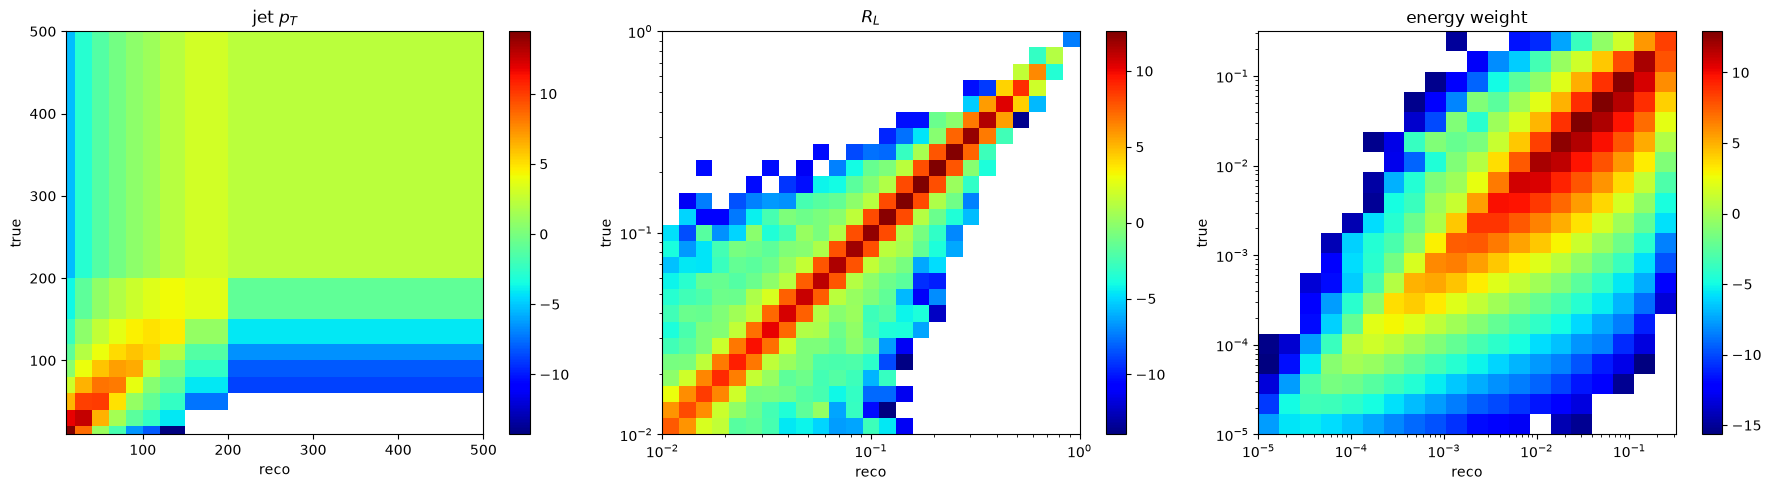

/tmp/ipykernel_1261058/1751521545.py:35: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')


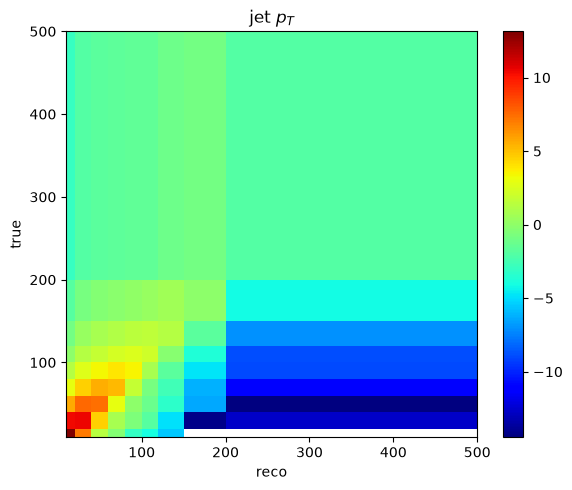

[array([2.24607582e+06, 4.68715114e+05, 4.26240530e+04, 8.05803024e+03,
       2.24114246e+03, 7.85158758e+02, 4.02764659e+02, 1.64030086e+02,
       4.60858966e+01]), array([3.28003072e+03, 4.79399562e+03, 7.05503361e+03, 1.08175425e+04,
       1.56401779e+04, 2.23928655e+04, 3.20911356e+04, 4.62150994e+04,
       6.47377574e+04, 9.08433080e+04, 1.24460395e+05, 1.67564972e+05,
       2.18598410e+05, 2.75667567e+05, 3.27052808e+05, 3.59666168e+05,
       3.54203578e+05, 2.96333184e+05, 2.01126475e+05, 1.02344472e+05,
       3.58483263e+04, 7.77350380e+03, 6.02288713e+02, 3.10607051e+00,
       6.31760351e-04]), array([1.31662021e-02, 9.61555205e-02, 5.41092110e-01, 2.49091249e+00,
       1.01296037e+01, 3.79477470e+01, 1.34015747e+02, 4.54898106e+02,
       1.50738606e+03, 4.85009954e+03, 1.49156920e+04, 4.27269898e+04,
       1.12792139e+05, 2.63160667e+05, 4.78344707e+05, 6.40811931e+05,
       6.31326408e+05, 4.18827464e+05, 1.54502770e+05, 4.70581434e+03])]
[7.32537785e+06 9.432189

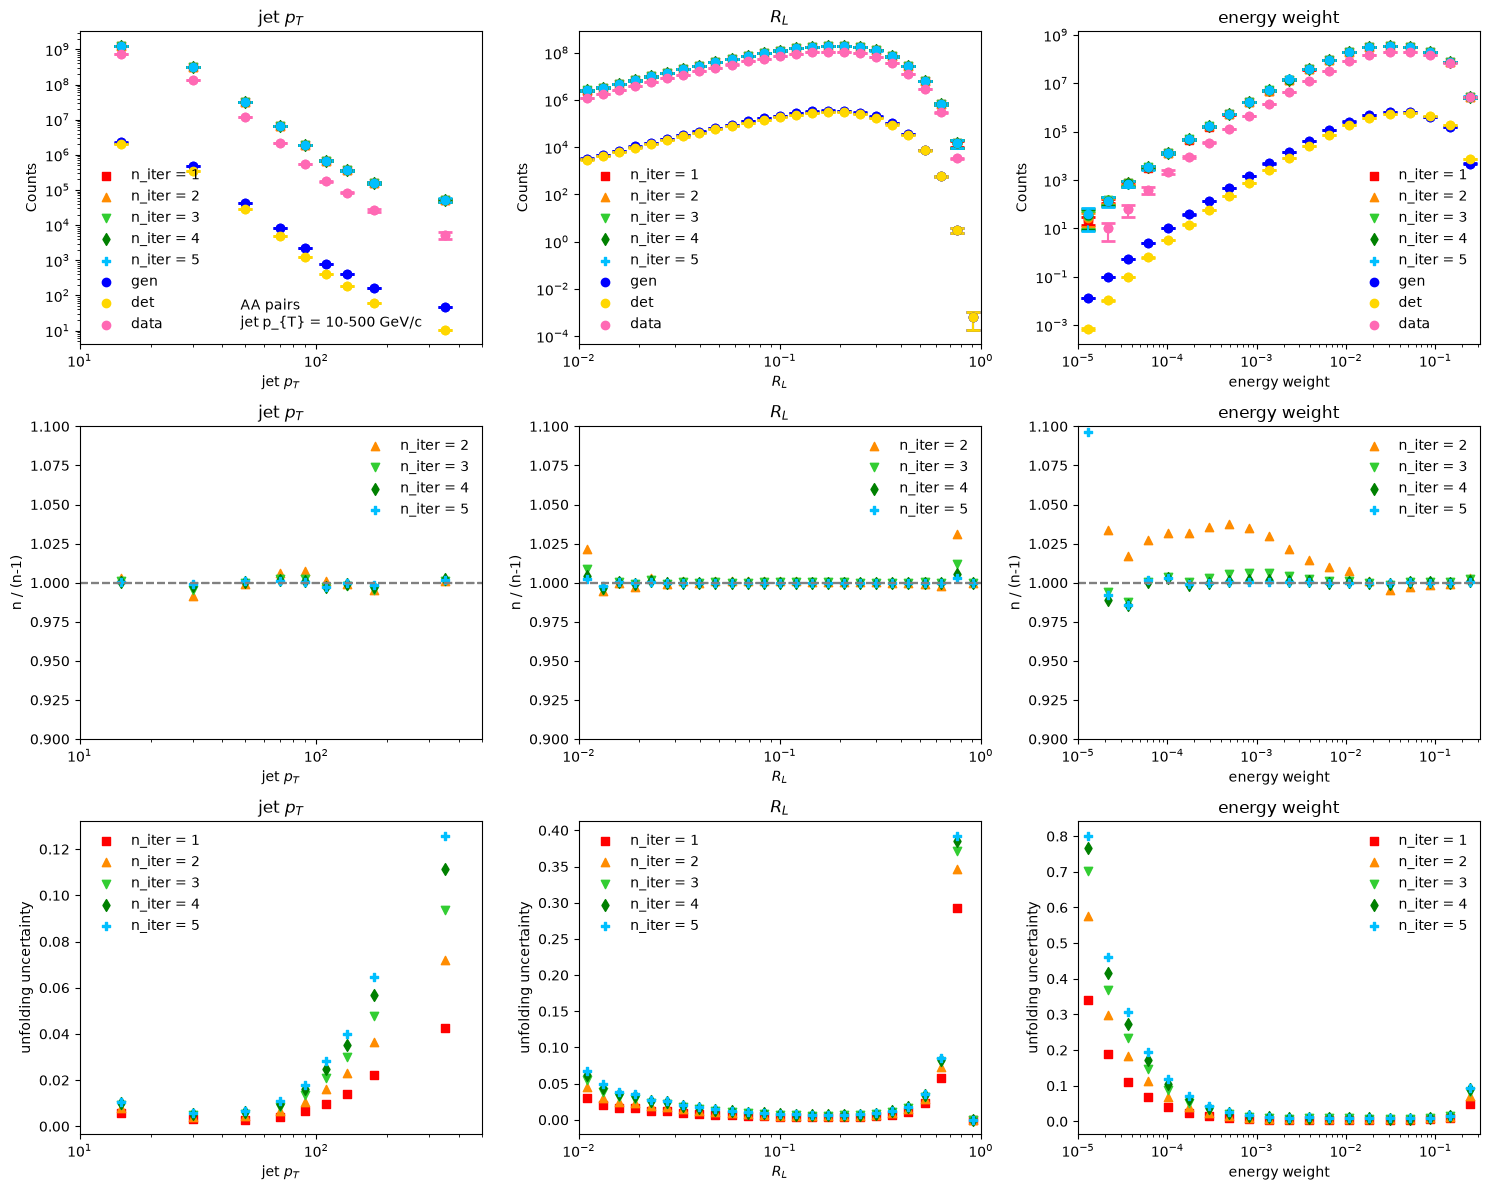

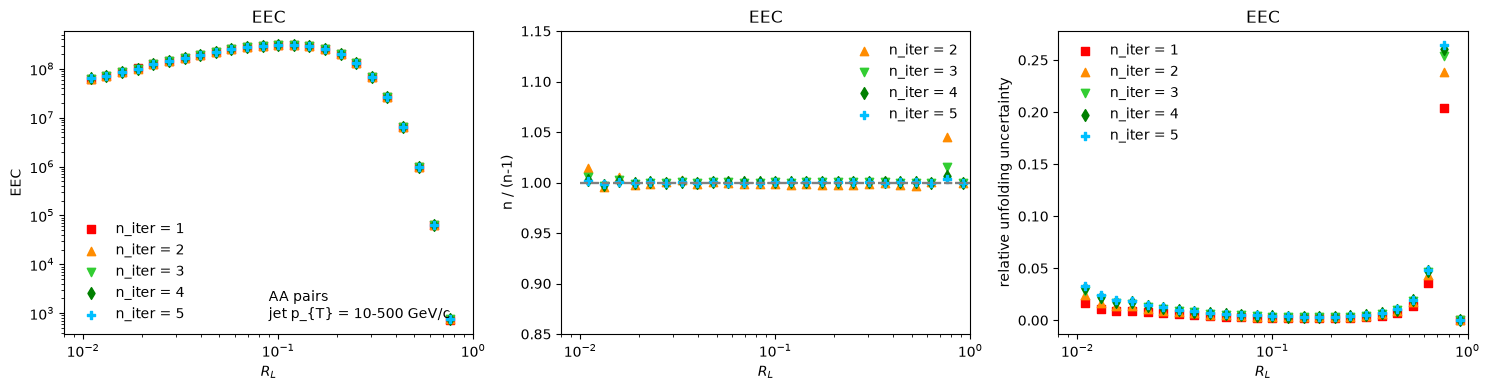

/tmp/ipykernel_1261058/3902168942.py:59: RuntimeWarning: invalid value encountered in divide
  raw_EEC_relerr = raw_EEC_err / raw_EEC


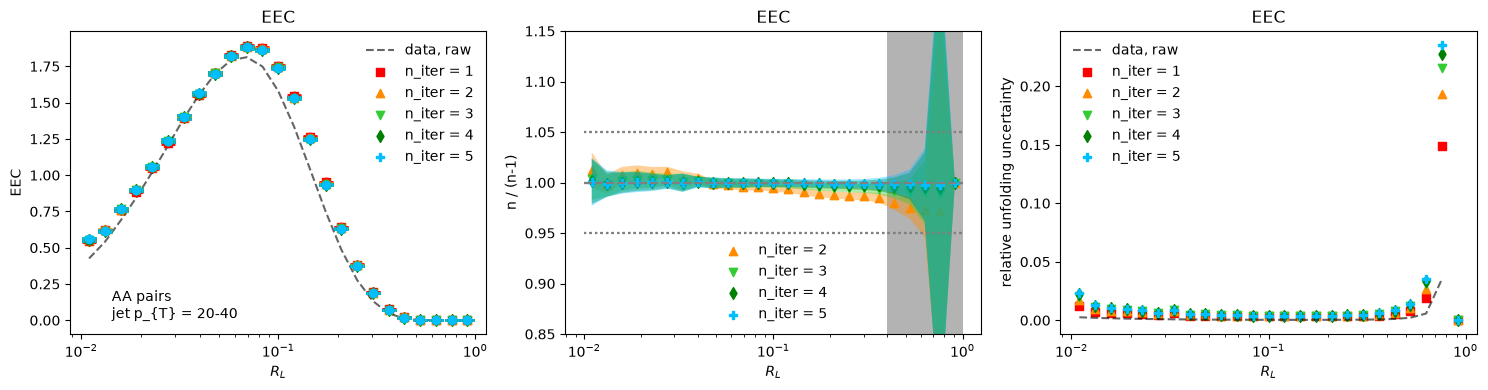

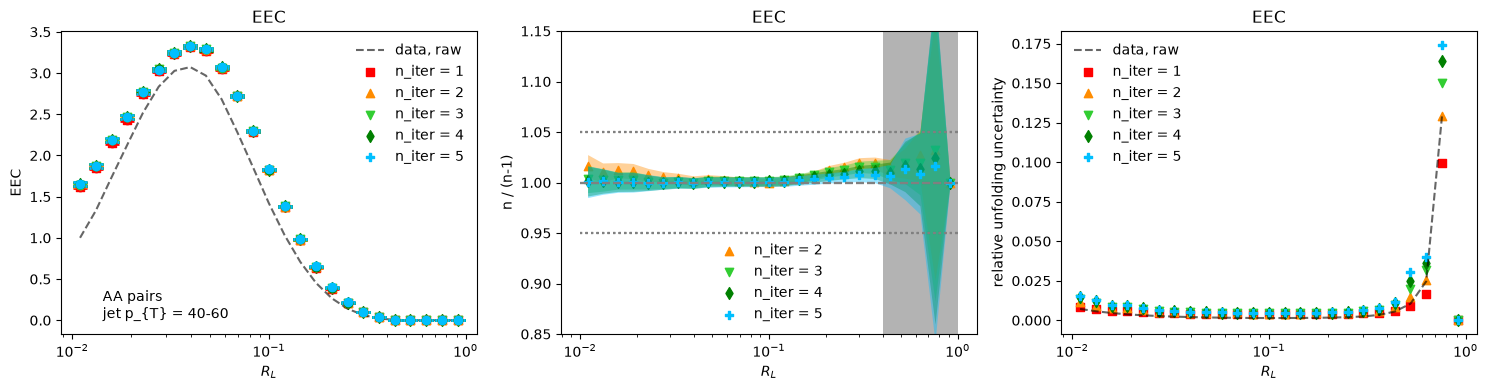

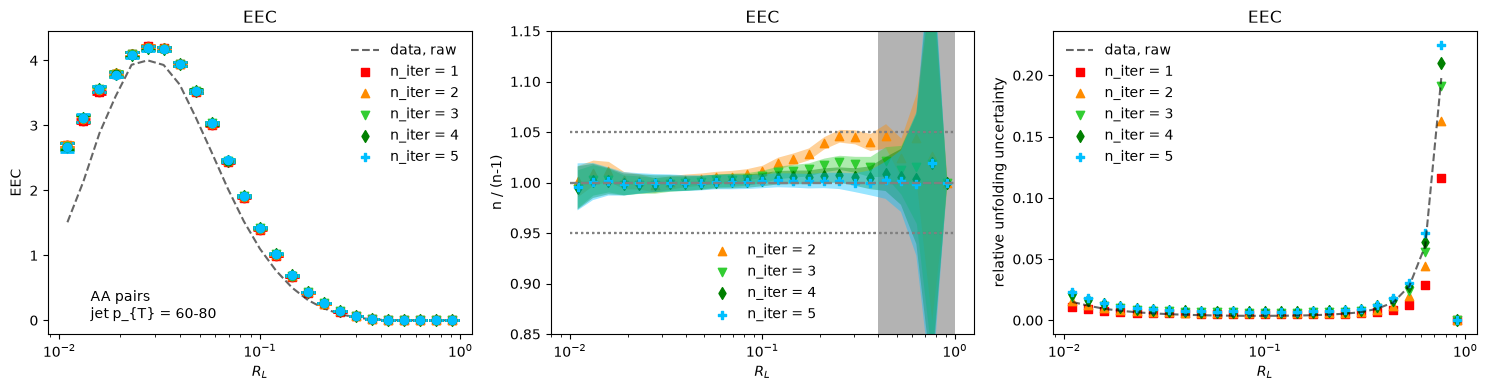

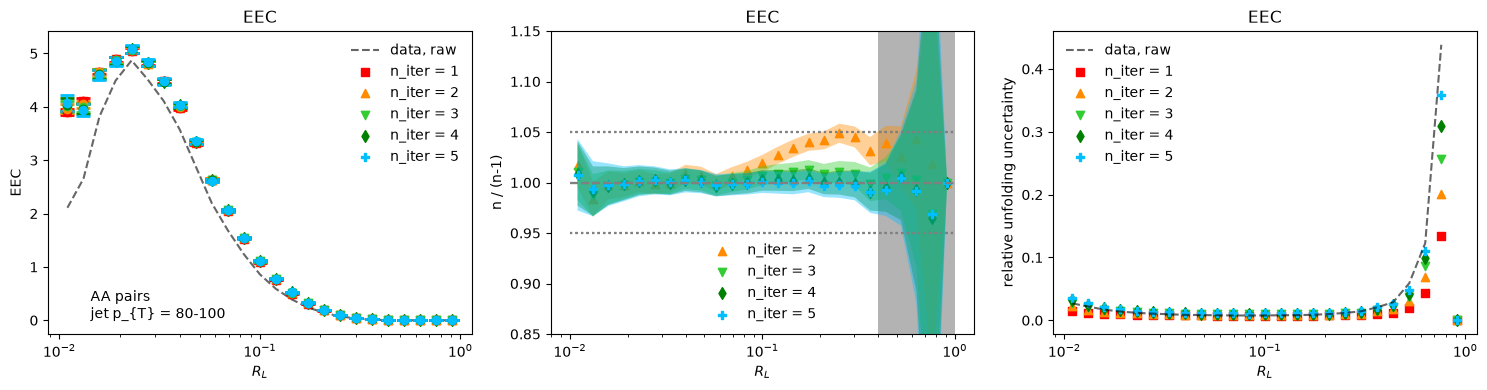

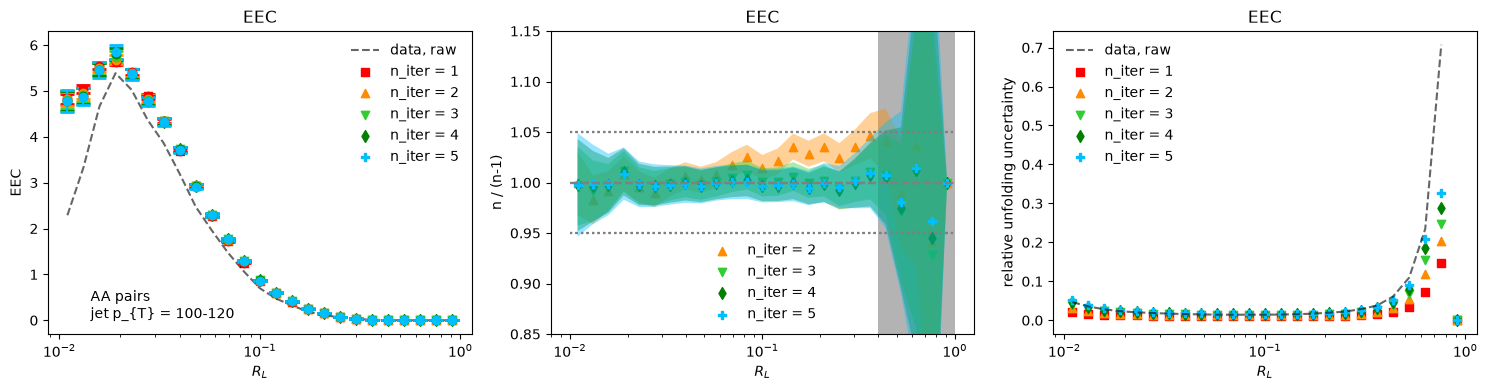

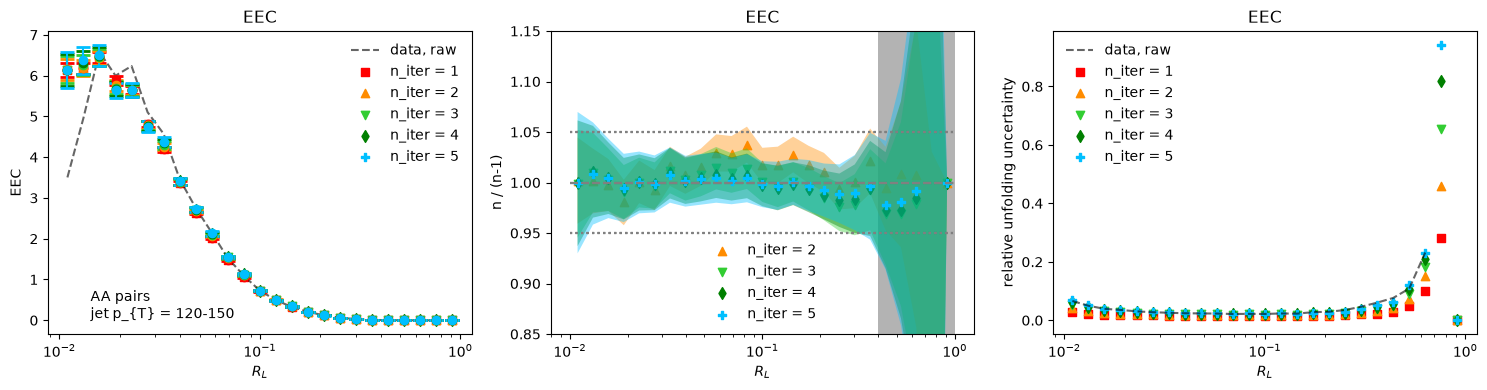

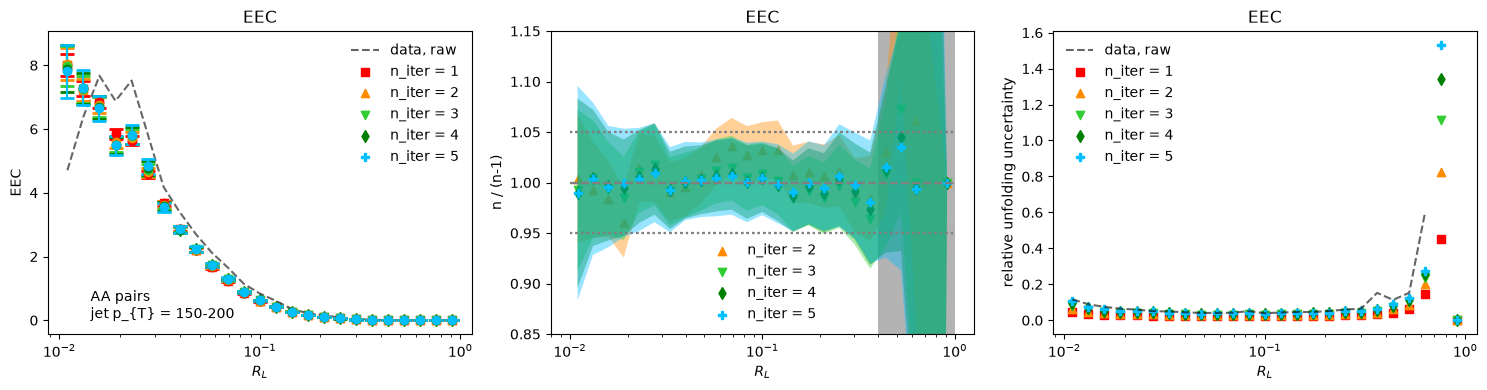

In [62]:
lab = "AA"
h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity = get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm) #, f_prefundold_gen)
matrix1D, matricies = get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true)
print_response_matricies(matrix1D, matricies, binning_reco, binning, labels)

theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err = get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded)
plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                        theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err)
plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning)

plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels)



[[5.11649774e+05 3.11647375e+04 2.74280655e+02 1.99967296e+01
  3.47434628e+00 9.20274220e-01 4.01037524e-01 1.51216906e-01
  5.30154275e-02]
 [1.17998494e+03 3.83336157e+04 1.93663617e+03 1.02790934e+02
  1.40912504e+01 3.31267990e+00 1.33241321e+00 4.61143151e-01
  1.39366128e-01]
 [3.79827653e+00 9.29055773e+01 1.60800169e+03 2.54975186e+02
  3.08886206e+01 6.23177776e+00 2.18518254e+00 6.68129189e-01
  1.73227371e-01]
 [7.09648325e-01 2.22115499e+00 1.93989180e+01 1.89248652e+02
  5.15883467e+01 1.01647344e+01 3.26636776e+00 8.80173987e-01
  1.97313988e-01]
 [4.68016845e-02 5.65138027e-01 9.91742642e-01 5.92695106e+00
  3.48727553e+01 1.32108932e+01 4.32929303e+00 1.08409907e+00
  2.10510831e-01]
 [1.67584110e-02 1.48237326e-01 2.89436064e-01 4.42006536e-01
  2.19025807e+00 8.31867839e+00 4.77229204e+00 1.24315020e+00
  2.19164750e-01]
 [3.91500351e-03 7.39563548e-03 3.63551291e-02 6.97108238e-02
  1.69025290e-01 7.65197820e-01 3.40822155e+00 1.74684803e+00
  3.17310702e-01]
 [0.00

/tmp/ipykernel_1261058/1751521545.py:16: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


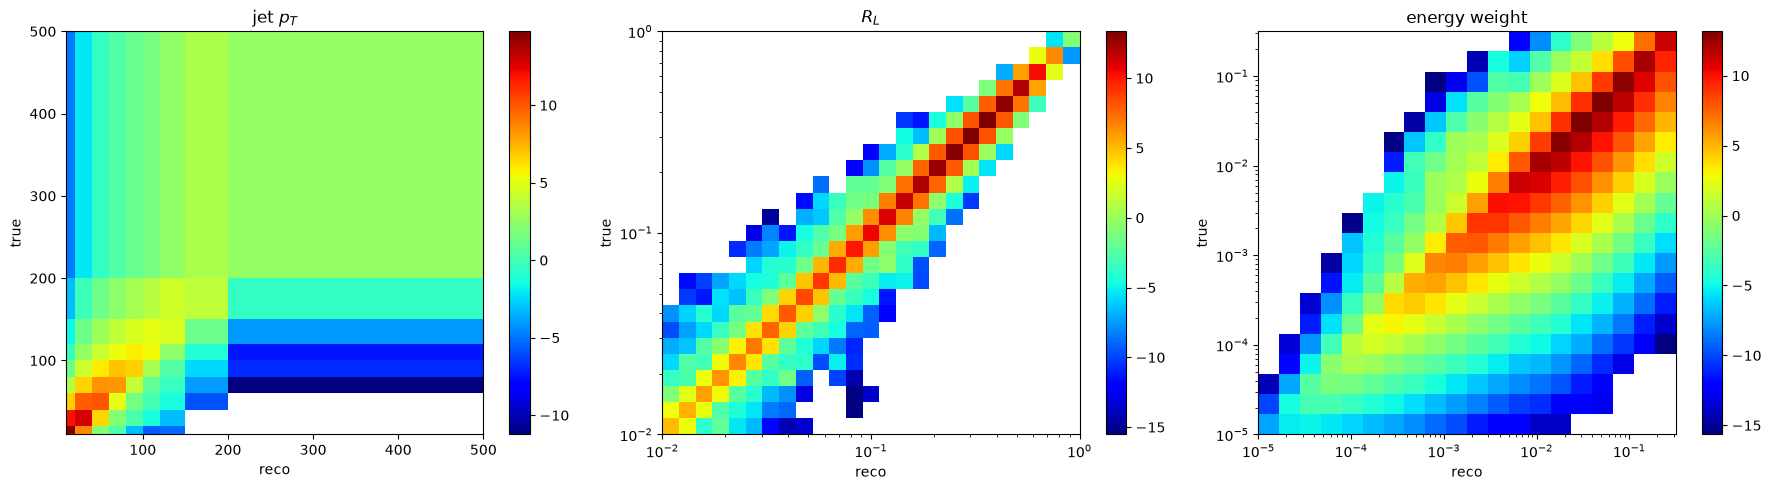

/tmp/ipykernel_1261058/1751521545.py:35: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')


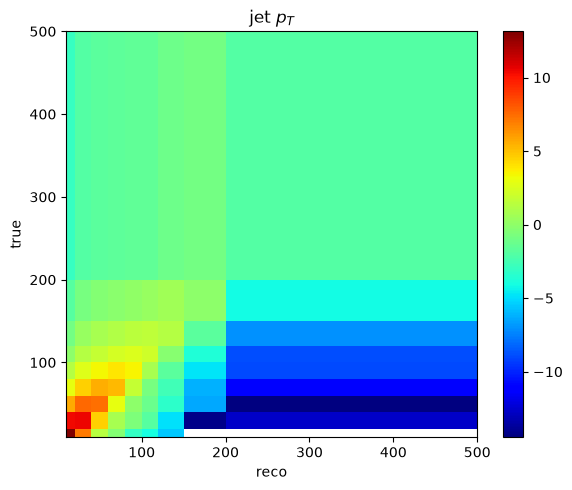

[array([3.12673851e+06, 5.10613309e+05, 4.33631796e+04, 8.38698701e+03,
       2.41173490e+03, 8.72216088e+02, 4.63811684e+02, 1.96568781e+02,
       5.90457914e+01]), array([1.73672406e+02, 2.35763153e+02, 4.03907107e+02, 5.59187652e+02,
       8.20644877e+02, 1.33611026e+03, 2.19767795e+03, 3.33785975e+03,
       5.38962742e+03, 8.54732421e+03, 1.44851572e+04, 2.39867558e+04,
       4.14380491e+04, 7.10840652e+04, 1.23529844e+05, 2.13904413e+05,
       3.56503926e+05, 5.52082020e+05, 7.41768492e+05, 7.74465442e+05,
       5.14061679e+05, 2.05954118e+05, 3.61234676e+04, 7.15716453e+02,
       4.45190354e-01]), array([2.03311058e-02, 1.45578764e-01, 7.88228802e-01, 3.54533233e+00,
       1.41359318e+01, 5.20033222e+01, 1.80716088e+02, 6.03216813e+02,
       1.97134495e+03, 6.26131663e+03, 1.90670303e+04, 5.45386510e+04,
       1.48228214e+05, 3.67941268e+05, 6.64663513e+05, 8.45252203e+05,
       7.74791249e+05, 4.98617773e+05, 2.25622188e+05, 8.52960423e+04])]
[7.11641612e+06 8.661292

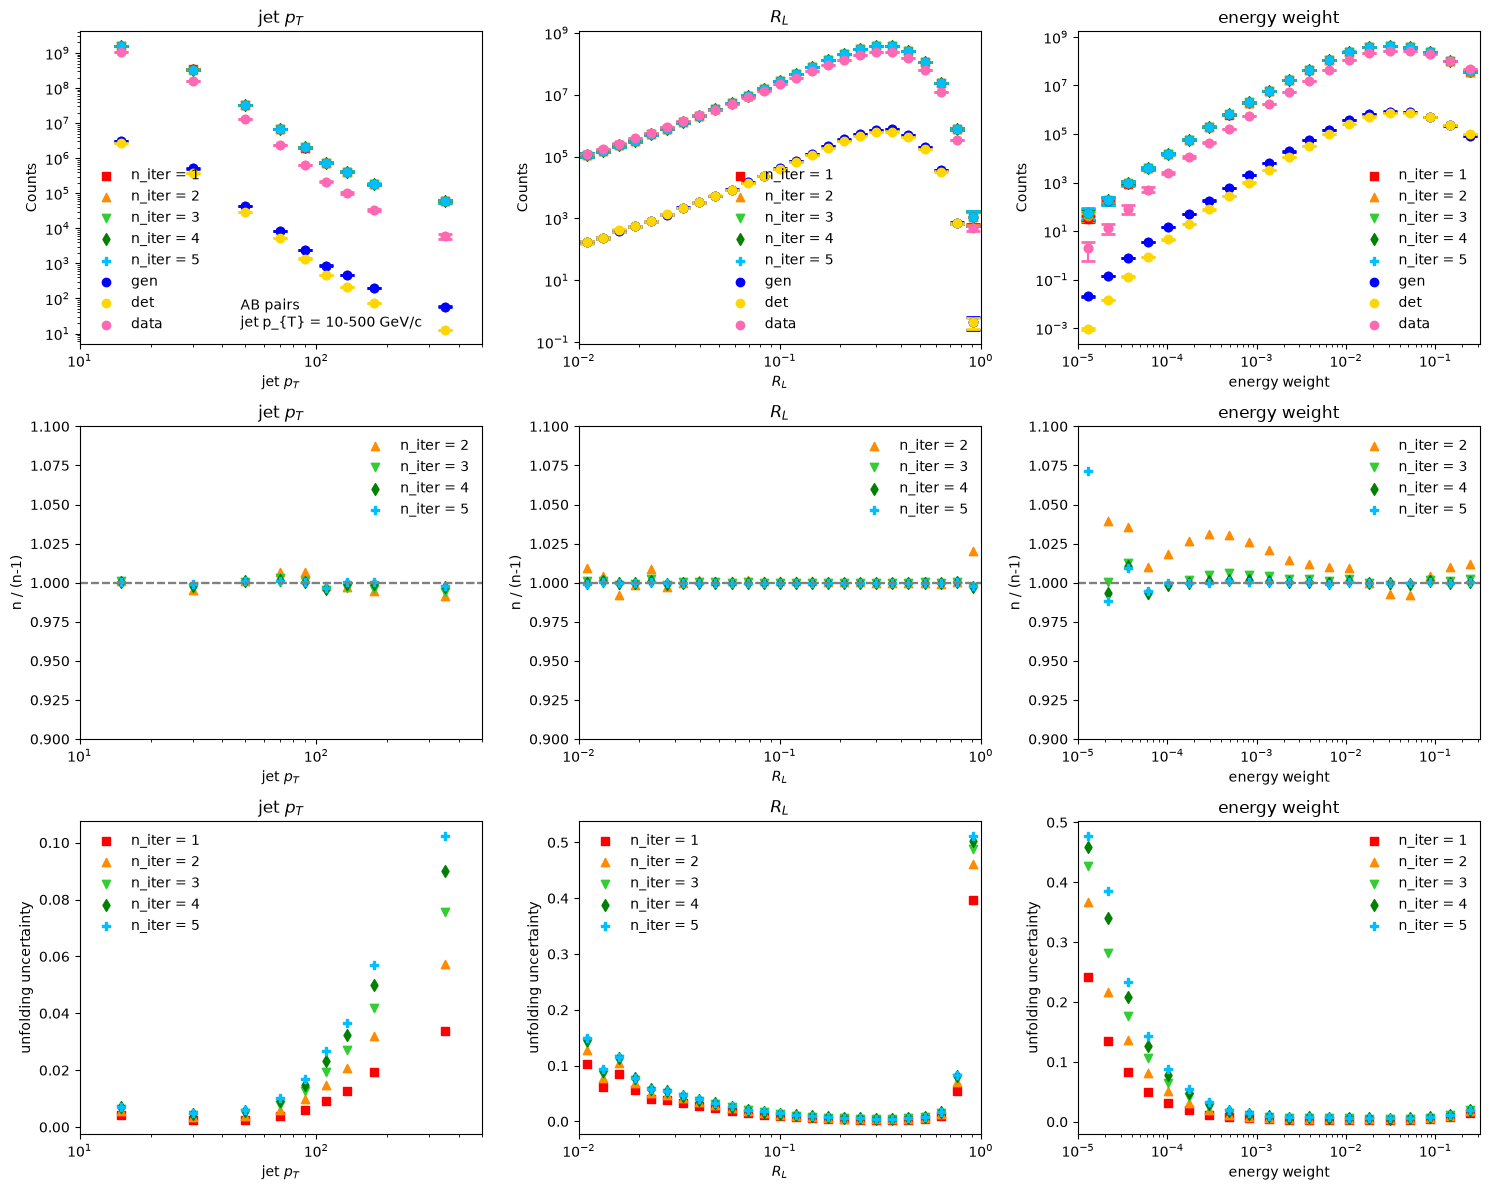

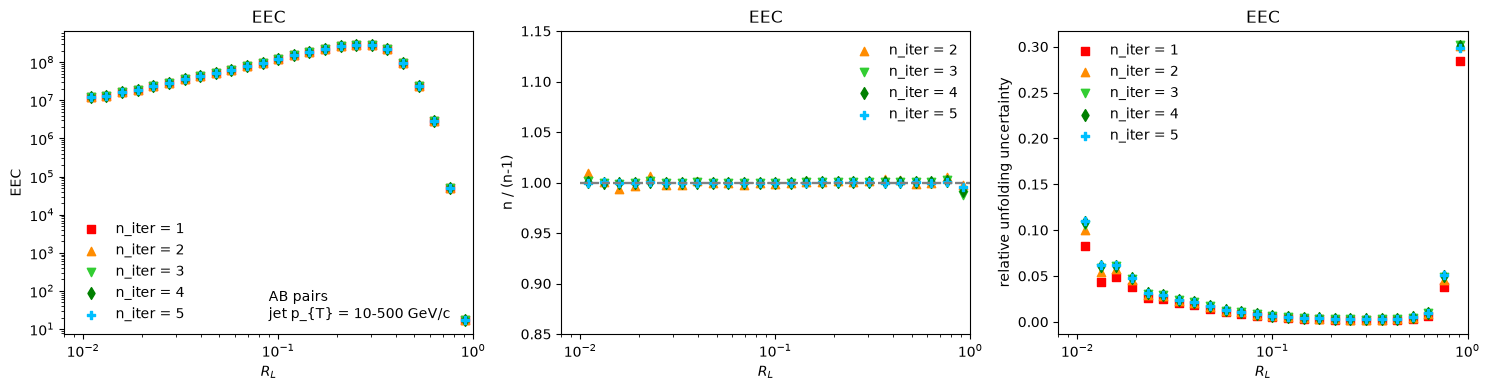

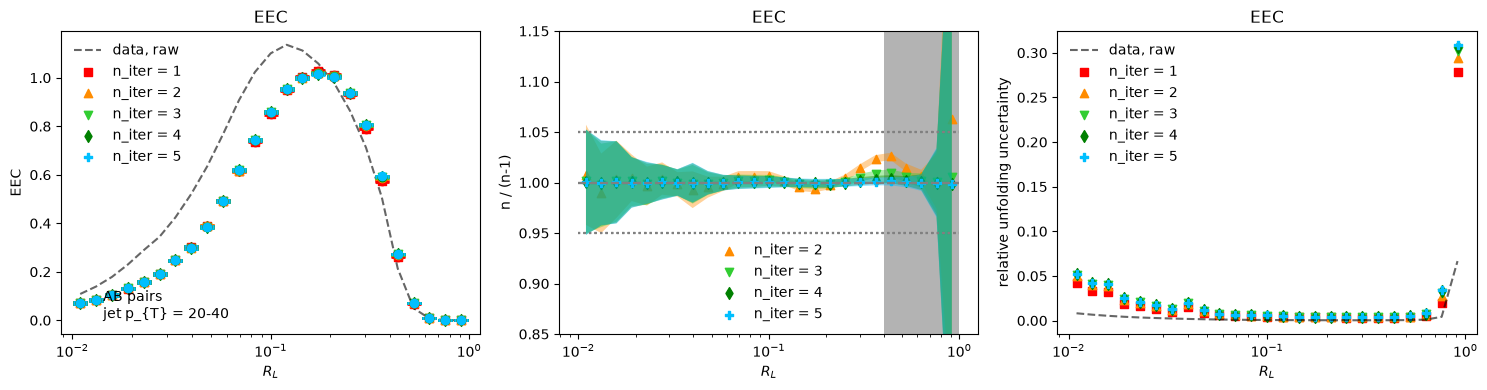

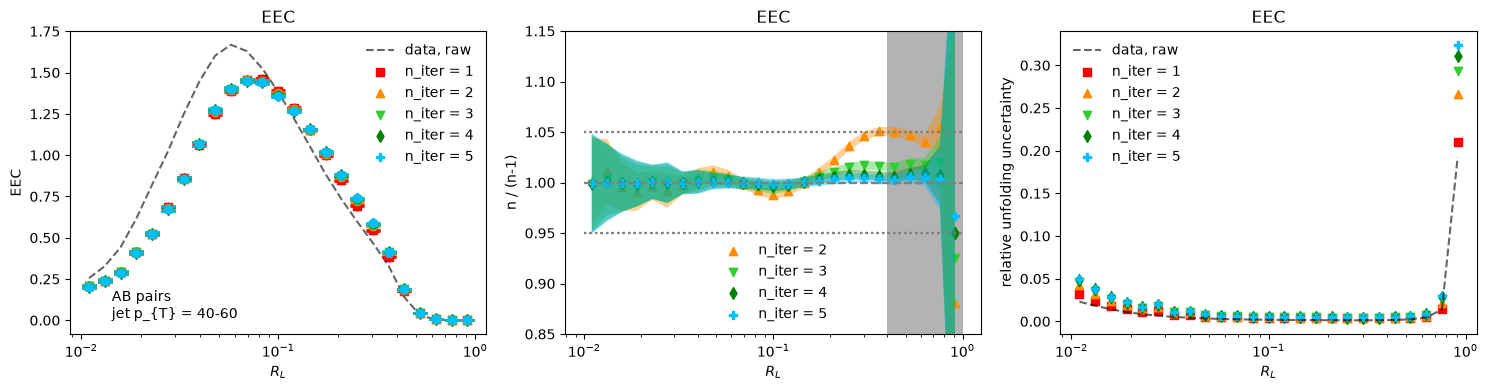

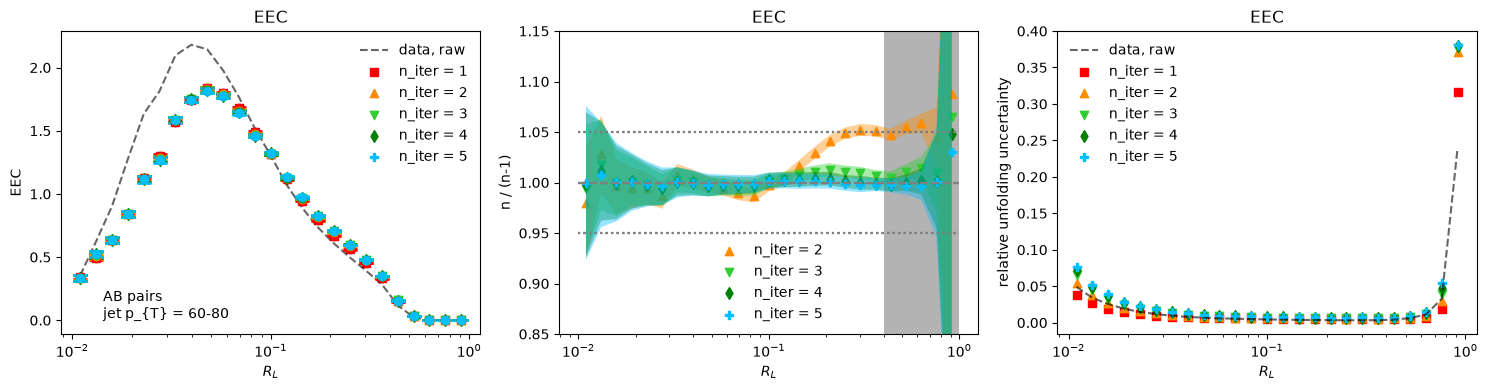

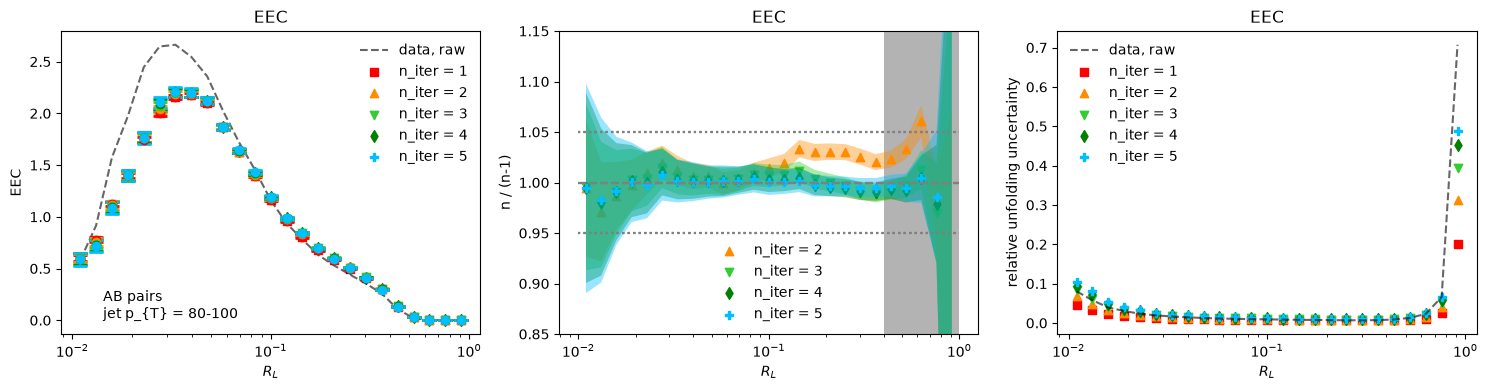

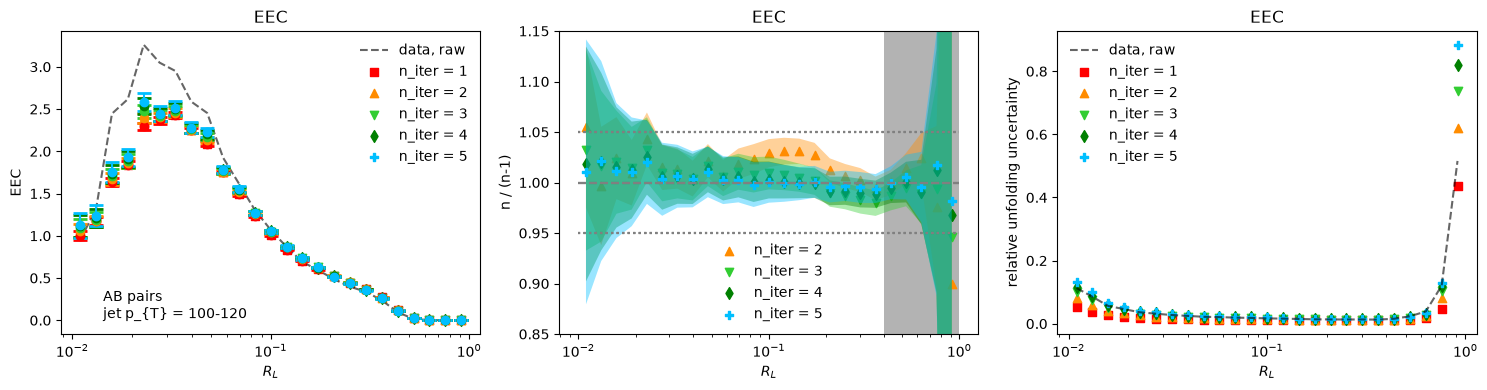

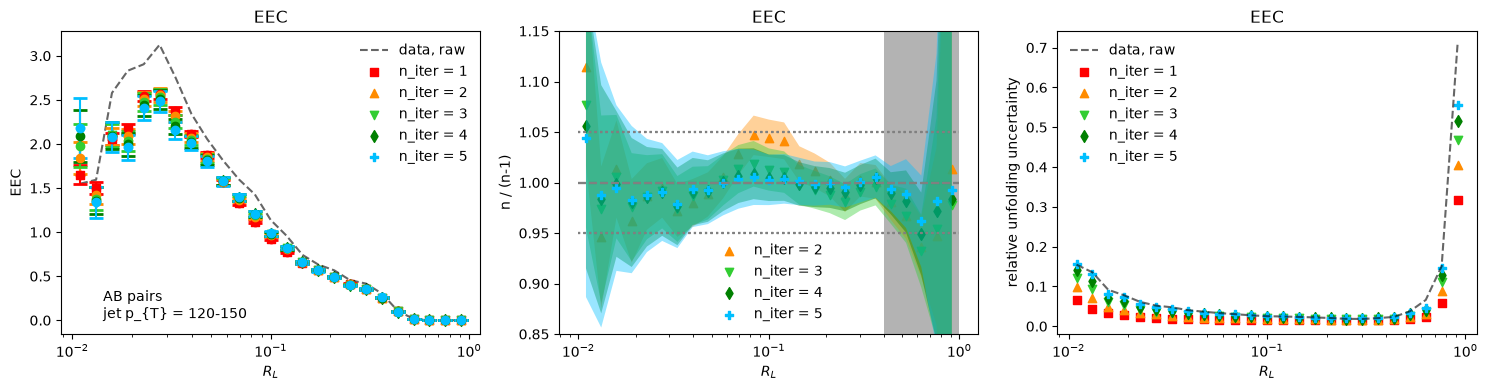

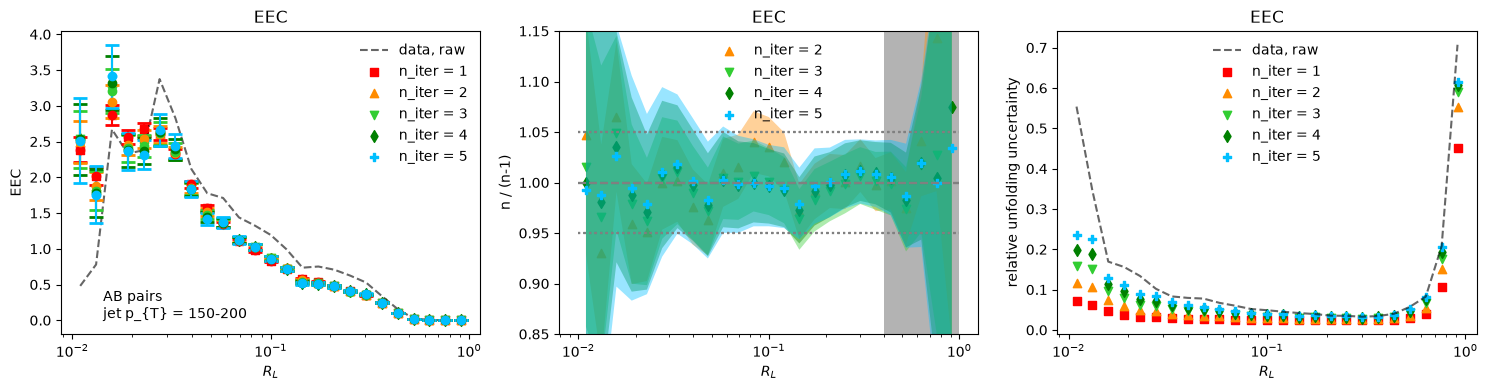

In [63]:
lab = "AB"
h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity = get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm) #, f_prefundold_gen)
matrix1D, matricies = get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true)
print_response_matricies(matrix1D, matricies, binning_reco, binning, labels)

theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err = get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded)
plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                        theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err)
plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning)

plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels)


[[5.11649774e+05 3.11647375e+04 2.74280655e+02 1.99967296e+01
  3.47434628e+00 9.20274220e-01 4.01037524e-01 1.51216906e-01
  5.30154275e-02]
 [1.17998494e+03 3.83336157e+04 1.93663617e+03 1.02790934e+02
  1.40912504e+01 3.31267990e+00 1.33241321e+00 4.61143151e-01
  1.39366128e-01]
 [3.79827653e+00 9.29055773e+01 1.60800169e+03 2.54975186e+02
  3.08886206e+01 6.23177776e+00 2.18518254e+00 6.68129189e-01
  1.73227371e-01]
 [7.09648325e-01 2.22115499e+00 1.93989180e+01 1.89248652e+02
  5.15883467e+01 1.01647344e+01 3.26636776e+00 8.80173987e-01
  1.97313988e-01]
 [4.68016845e-02 5.65138027e-01 9.91742642e-01 5.92695106e+00
  3.48727553e+01 1.32108932e+01 4.32929303e+00 1.08409907e+00
  2.10510831e-01]
 [1.67584110e-02 1.48237326e-01 2.89436064e-01 4.42006536e-01
  2.19025807e+00 8.31867839e+00 4.77229204e+00 1.24315020e+00
  2.19164750e-01]
 [3.91500351e-03 7.39563548e-03 3.63551291e-02 6.97108238e-02
  1.69025290e-01 7.65197820e-01 3.40822155e+00 1.74684803e+00
  3.17310702e-01]
 [0.00

/tmp/ipykernel_1261058/1751521545.py:16: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


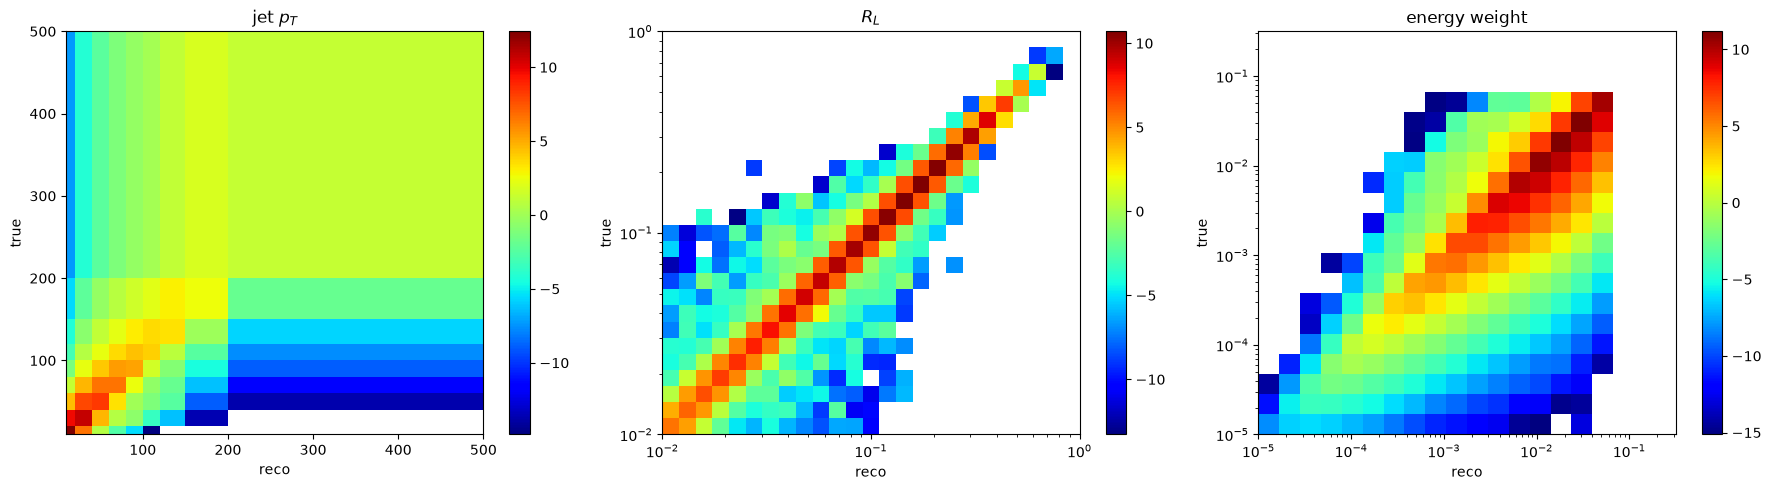

/tmp/ipykernel_1261058/1751521545.py:35: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')


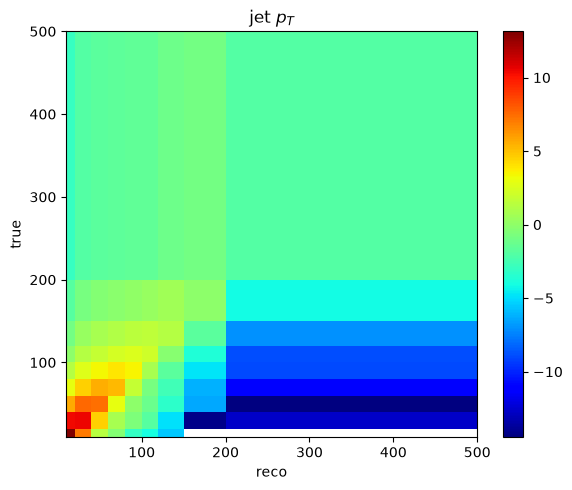

[array([2.81812325e+05, 6.63994180e+04, 7.10463137e+03, 1.56103548e+03,
       4.89379842e+02, 1.88999332e+02, 1.06254551e+02, 4.76975843e+01,
       1.49645150e+01]), array([4.55652321e+02, 6.27236497e+02, 9.77468882e+02, 1.44128636e+03,
       2.06223335e+03, 2.87517961e+03, 4.40112724e+03, 6.28283296e+03,
       8.94281821e+03, 1.25236285e+04, 1.74085212e+04, 2.39323105e+04,
       3.17271937e+04, 4.05581382e+04, 4.84760561e+04, 5.06237884e+04,
       4.60909651e+04, 3.25755541e+04, 1.81273524e+04, 6.34740574e+03,
       1.15593154e+03, 1.09525995e+02, 2.49694200e+00, 1.97571342e-03,
       0.00000000e+00]), array([7.12124244e-03, 5.39014613e-02, 2.95599495e-01, 1.33011180e+00,
       5.36013174e+00, 1.93452370e+01, 6.60297468e+01, 2.15533450e+02,
       6.75616154e+02, 2.04620448e+03, 6.40909252e+03, 1.67077400e+04,
       3.71467798e+04, 7.39011389e+04, 1.03082153e+05, 8.62666621e+04,
       3.11813634e+04, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00])]
[2.68043622e+06 3.921257

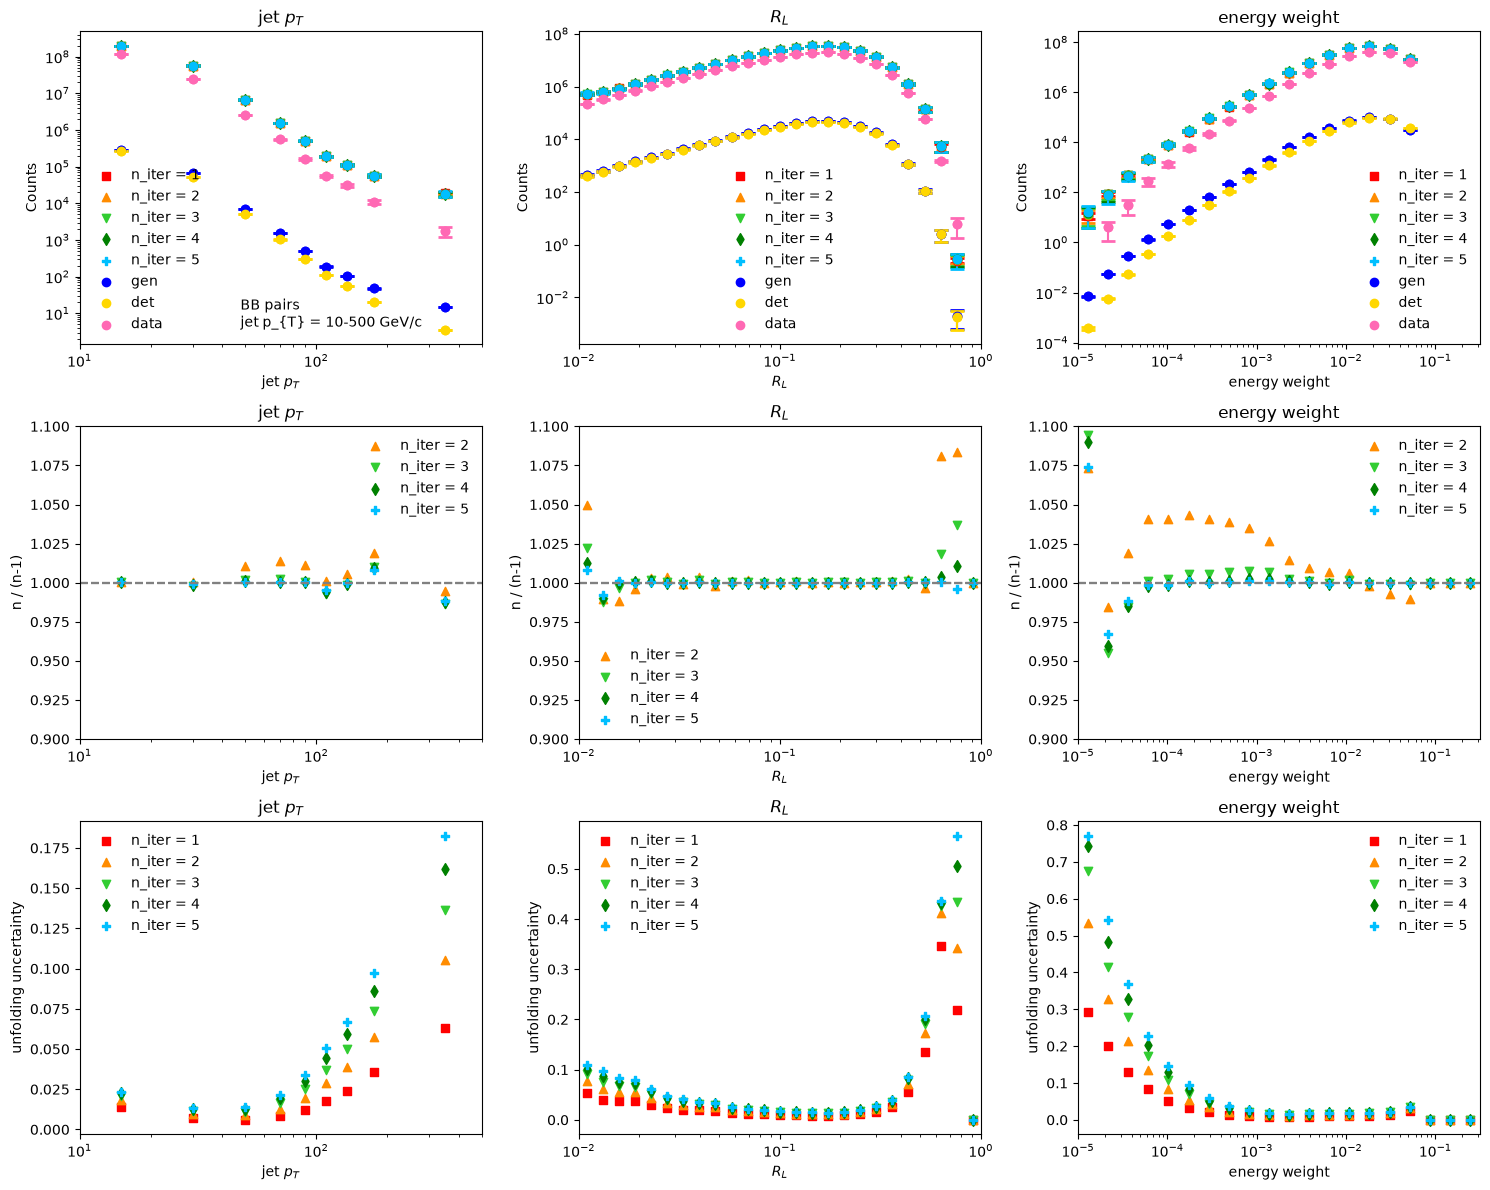

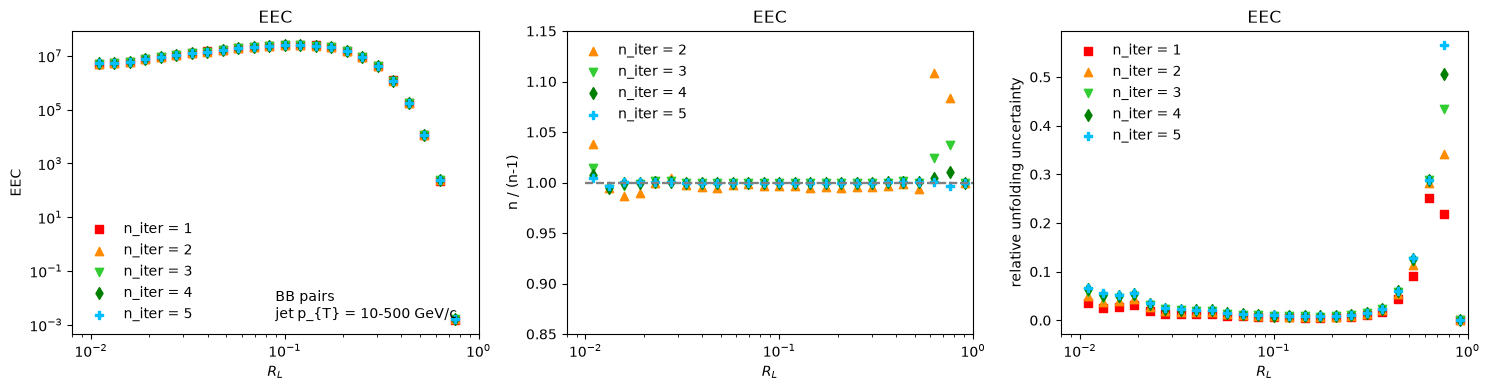

/tmp/ipykernel_1261058/3902168942.py:59: RuntimeWarning: invalid value encountered in divide
  raw_EEC_relerr = raw_EEC_err / raw_EEC


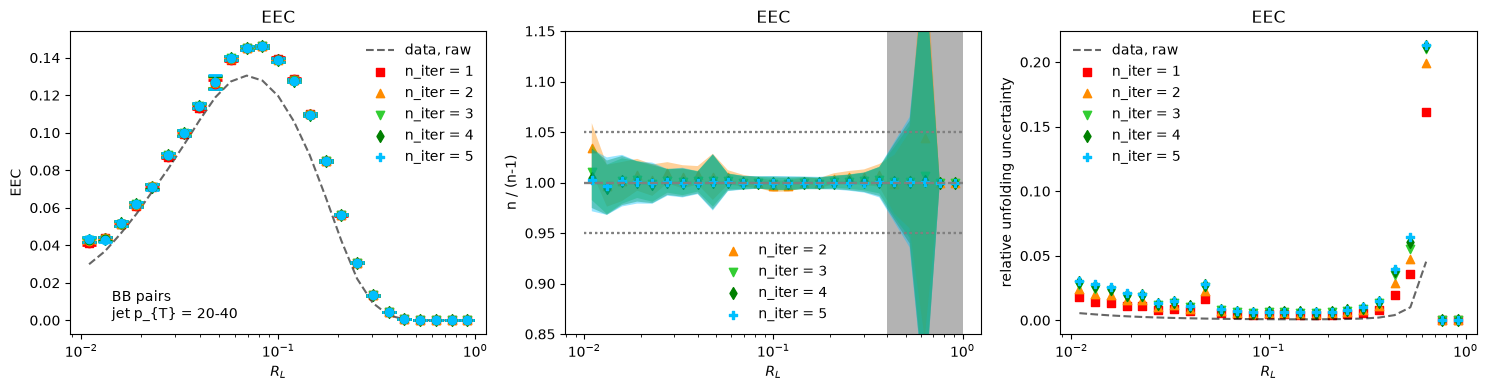

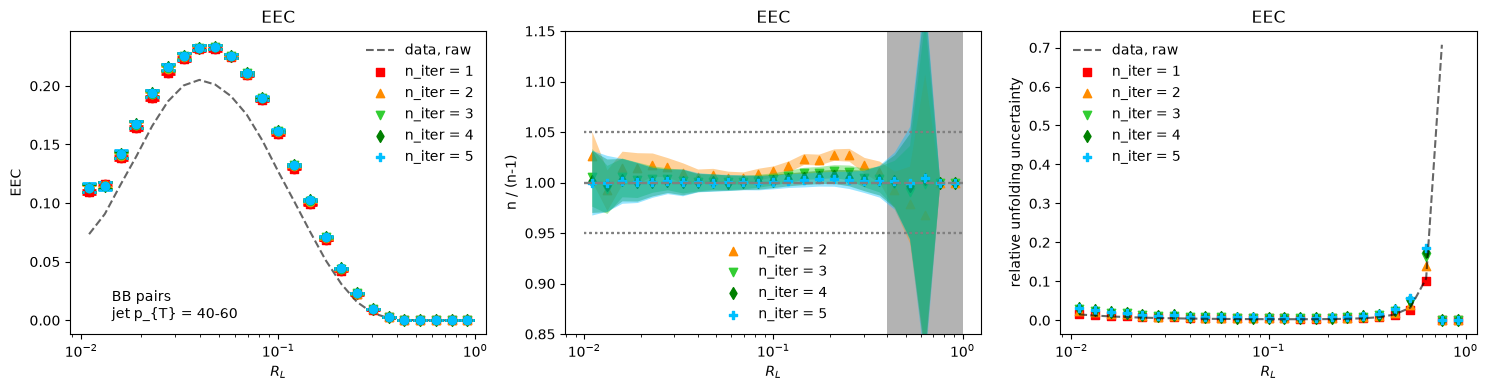

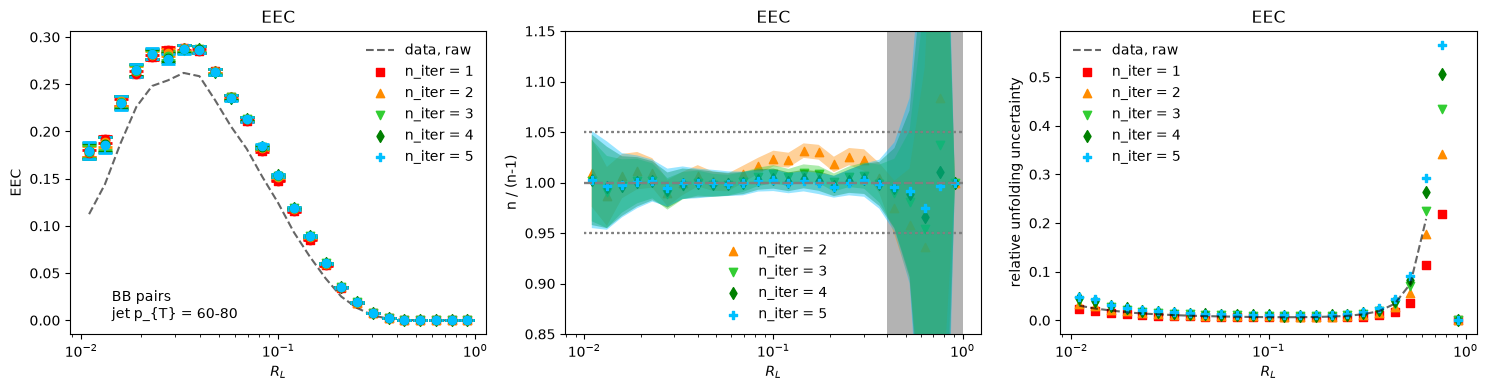

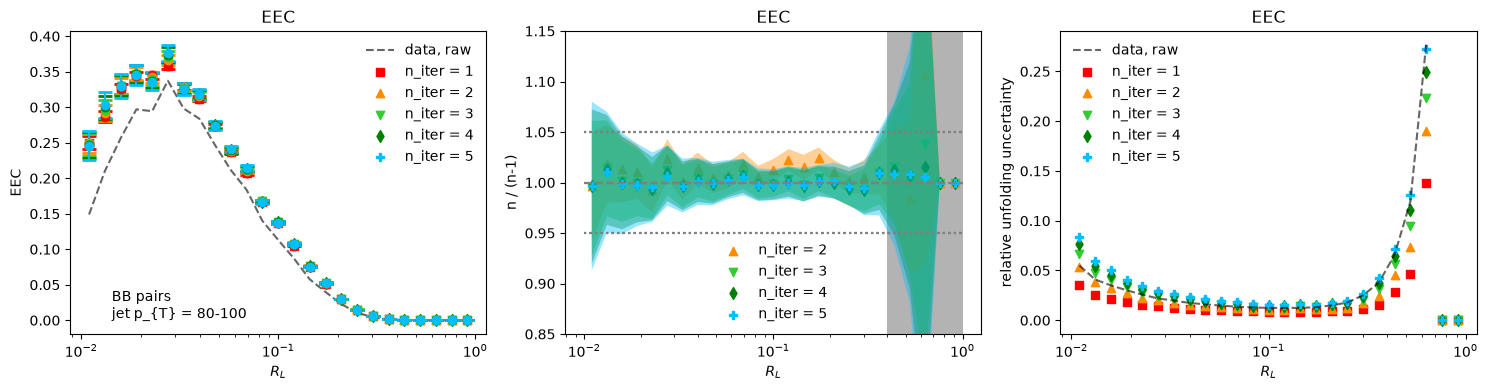

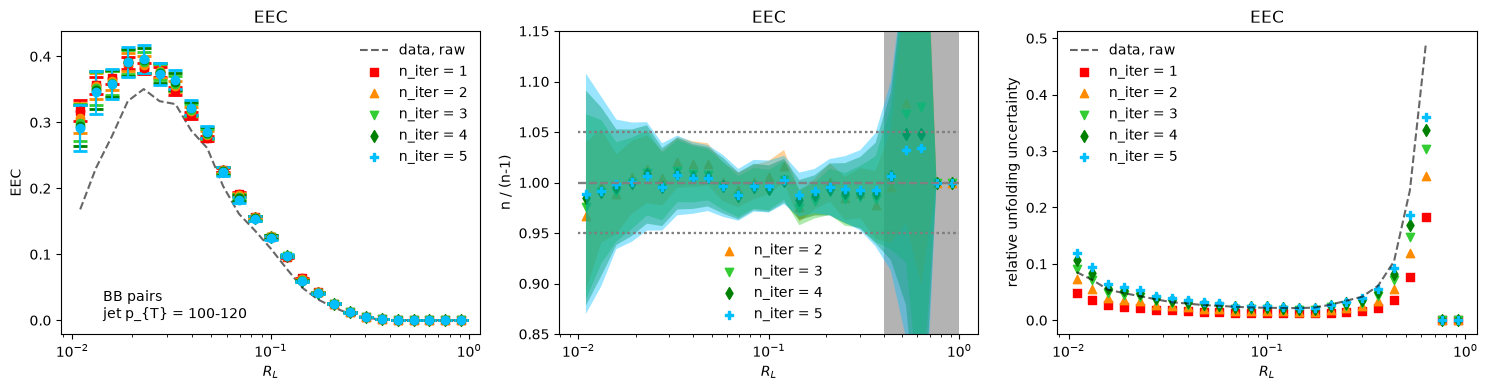

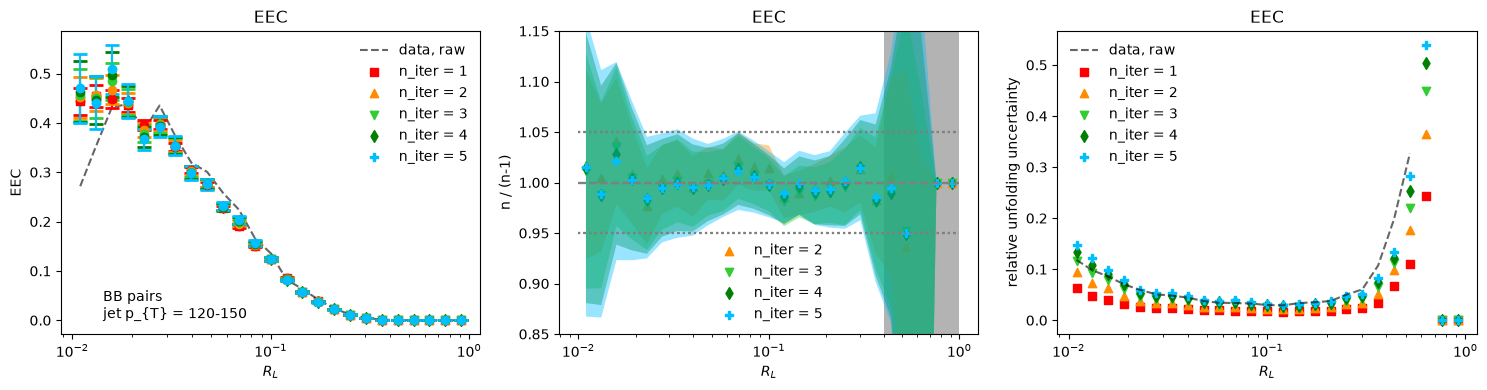

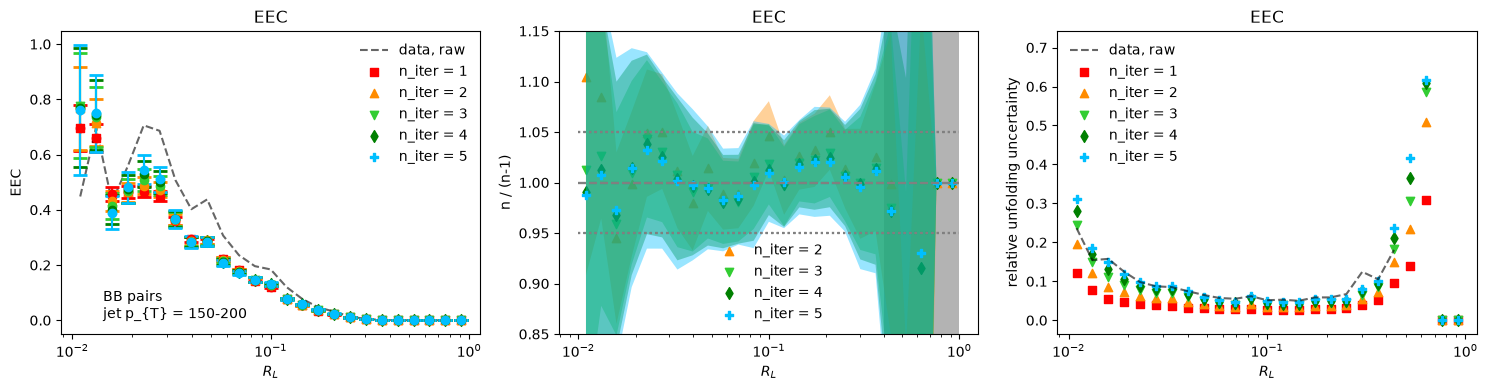

In [64]:
lab = "BB"
h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity = get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm) #, f_prefundold_gen)
matrix1D, matricies = get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true)
print_response_matricies(matrix1D, matricies, binning_reco, binning, labels)

theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err = get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded)
plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                        theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err)
plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning)

plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels)


[[5.11649774e+05 3.11647375e+04 2.74280655e+02 1.99967296e+01
  3.47434628e+00 9.20274220e-01 4.01037524e-01 1.51216906e-01
  5.30154275e-02]
 [1.17998494e+03 3.83336157e+04 1.93663617e+03 1.02790934e+02
  1.40912504e+01 3.31267990e+00 1.33241321e+00 4.61143151e-01
  1.39366128e-01]
 [3.79827653e+00 9.29055773e+01 1.60800169e+03 2.54975186e+02
  3.08886206e+01 6.23177776e+00 2.18518254e+00 6.68129189e-01
  1.73227371e-01]
 [7.09648325e-01 2.22115499e+00 1.93989180e+01 1.89248652e+02
  5.15883467e+01 1.01647344e+01 3.26636776e+00 8.80173987e-01
  1.97313988e-01]
 [4.68016845e-02 5.65138027e-01 9.91742642e-01 5.92695106e+00
  3.48727553e+01 1.32108932e+01 4.32929303e+00 1.08409907e+00
  2.10510831e-01]
 [1.67584110e-02 1.48237326e-01 2.89436064e-01 4.42006536e-01
  2.19025807e+00 8.31867839e+00 4.77229204e+00 1.24315020e+00
  2.19164750e-01]
 [3.91500351e-03 7.39563548e-03 3.63551291e-02 6.97108238e-02
  1.69025290e-01 7.65197820e-01 3.40822155e+00 1.74684803e+00
  3.17310702e-01]
 [0.00

/tmp/ipykernel_1261058/1751521545.py:16: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


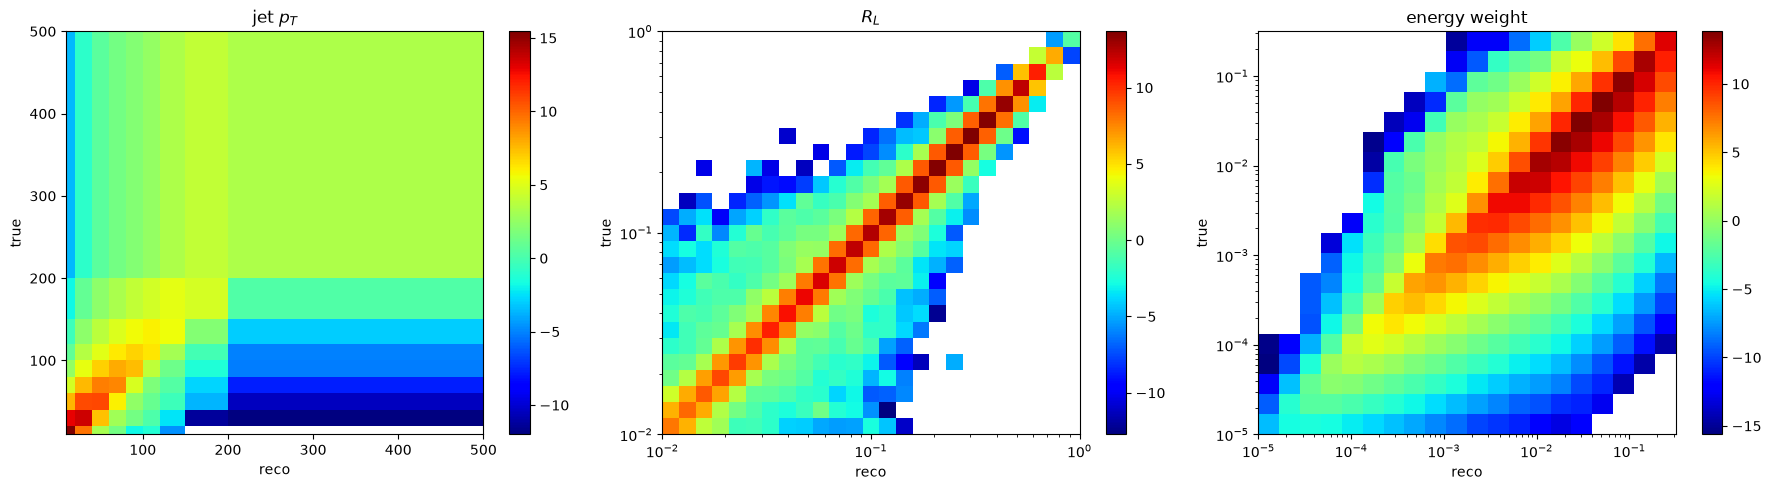

/tmp/ipykernel_1261058/1751521545.py:35: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')


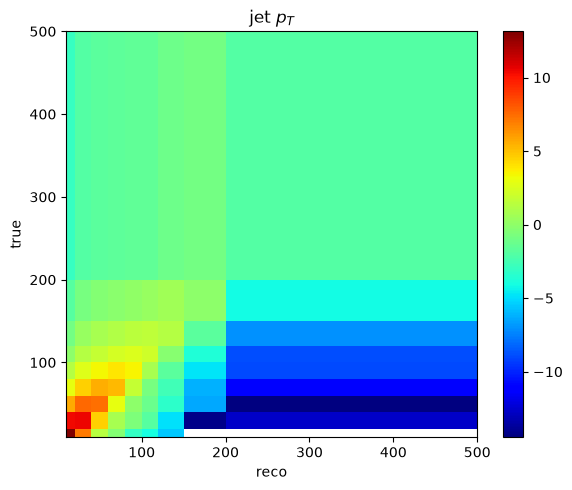

[array([6.38346842e+06, 1.22054093e+06, 1.08697171e+05, 2.09718730e+04,
       5.97772314e+03, 2.14530054e+03, 1.13086102e+03, 4.76466542e+02,
       1.42088843e+02]), array([4.29232575e+03, 6.23159362e+03, 9.26354220e+03, 1.41419836e+04,
       2.04353774e+04, 2.93772494e+04, 4.26271990e+04, 6.16483985e+04,
       8.77945748e+04, 1.24460596e+05, 1.74753598e+05, 2.42165321e+05,
       3.31028088e+05, 4.44317691e+05, 5.80014302e+05, 7.34662938e+05,
       8.94990032e+05, 1.03167254e+06, 1.09348816e+06, 9.68083137e+05,
       5.87161697e+05, 2.22644226e+05, 3.75714717e+04, 7.24351151e+02,
       4.45822115e-01]), array([5.11840207e-02, 3.64188808e-01, 1.96779843e+00, 8.83329572e+00,
       3.52974475e+01, 1.29770072e+02, 4.52114253e+02, 1.51557828e+03,
       4.96196684e+03, 1.57791391e+04, 4.84971070e+04, 1.36854884e+05,
       3.56708785e+05, 8.29157291e+05, 1.43831407e+06, 1.78406723e+06,
       1.59982657e+06, 1.00798979e+06, 4.25974393e+05, 9.32756361e+04])]
[1.10952148e+07 1.382015

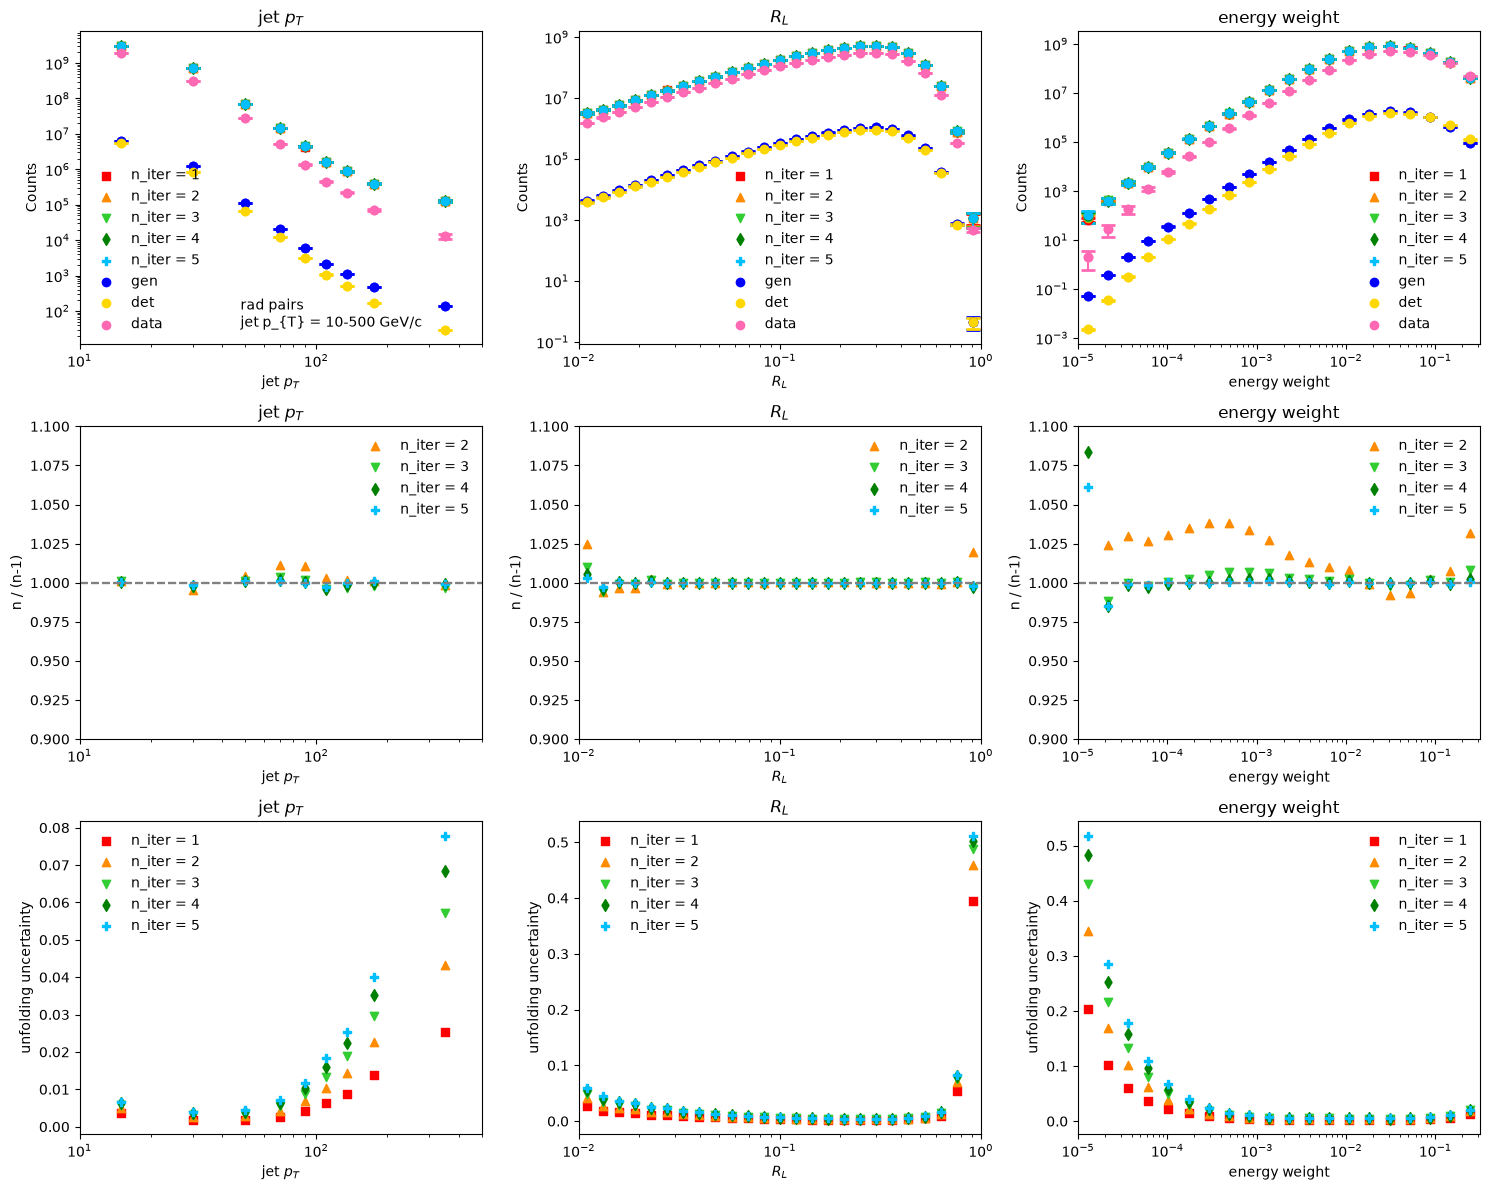

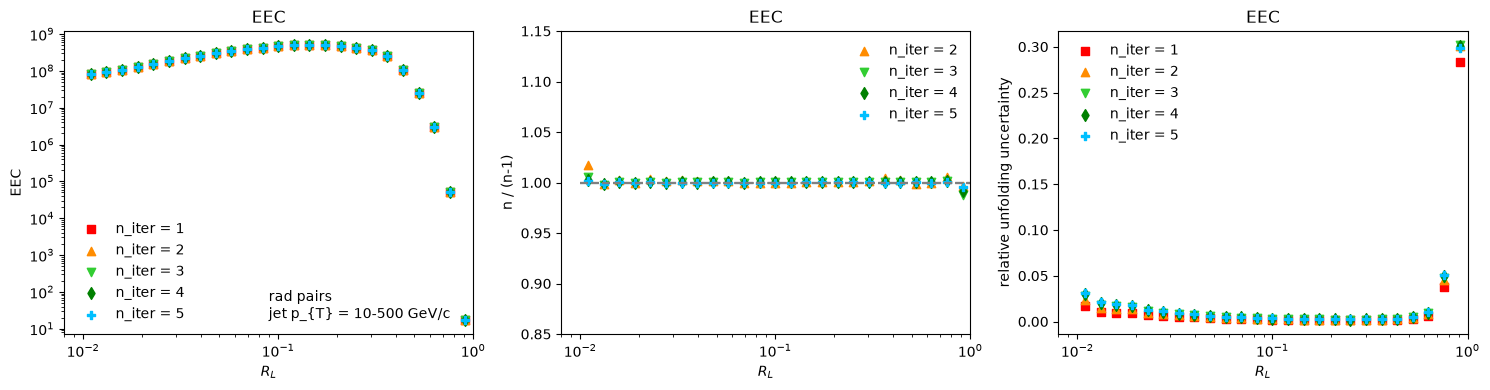

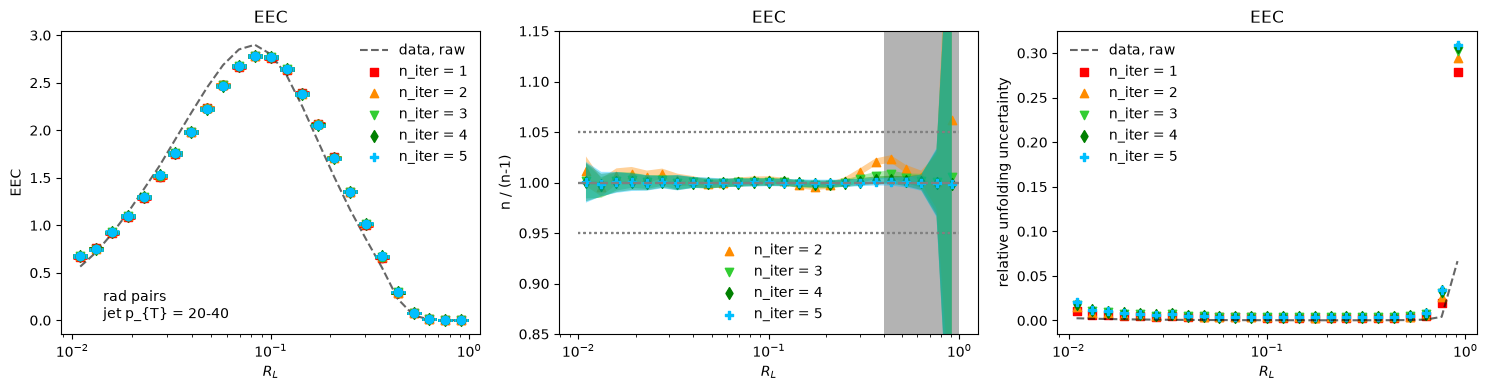

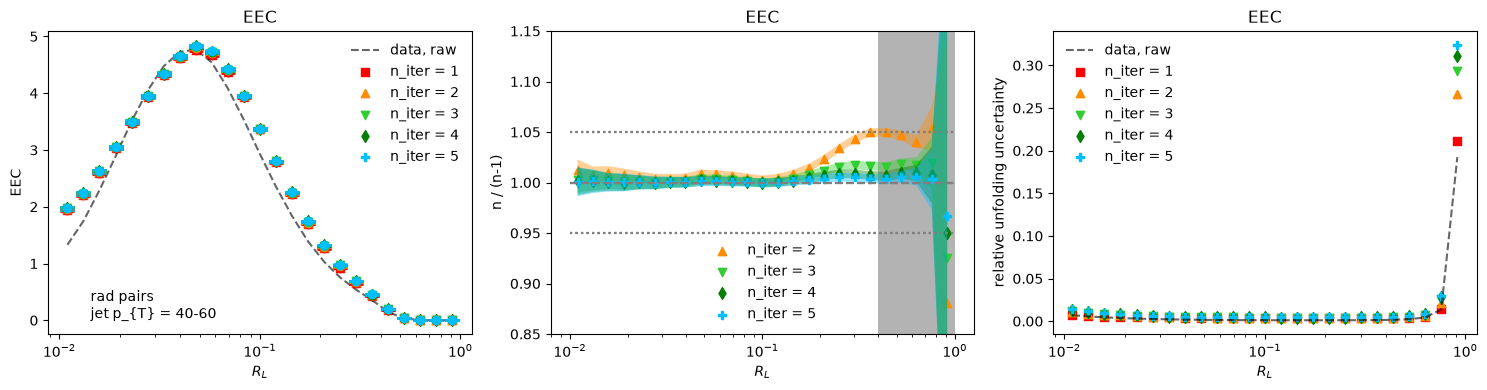

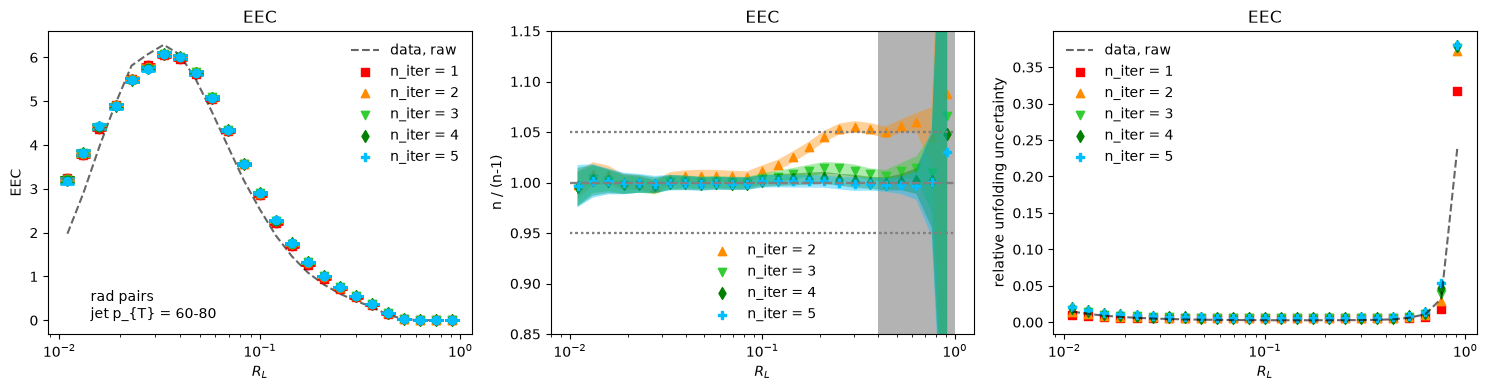

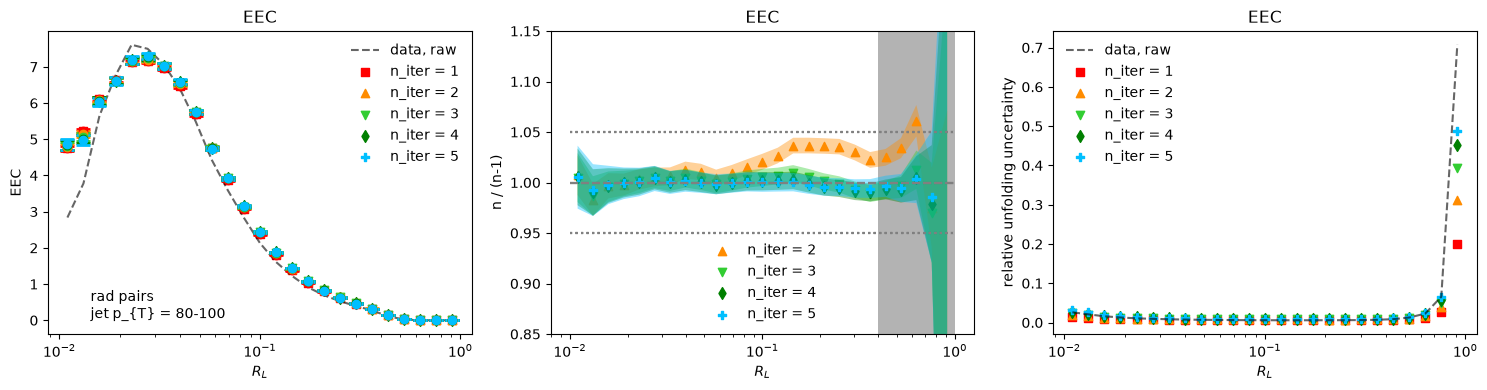

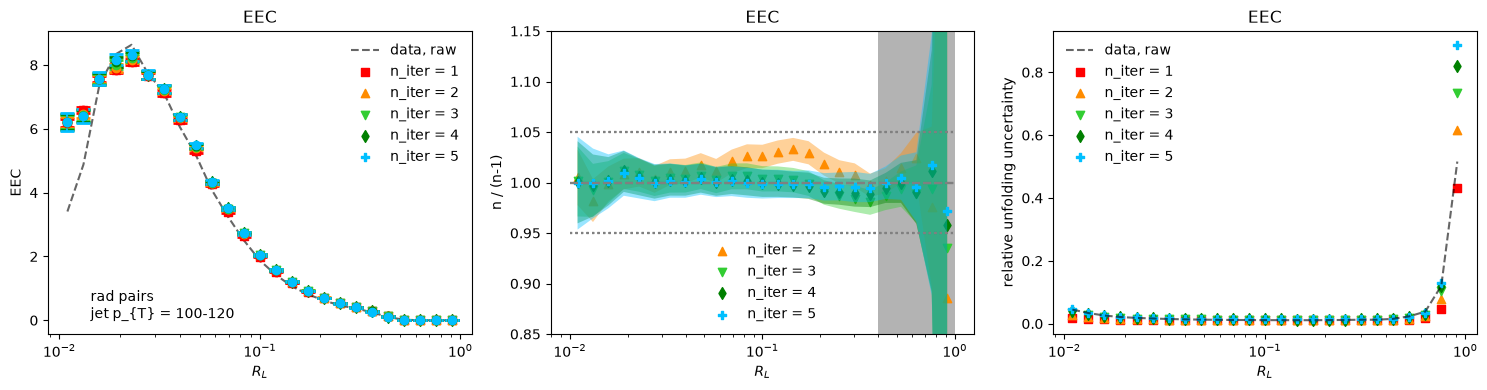

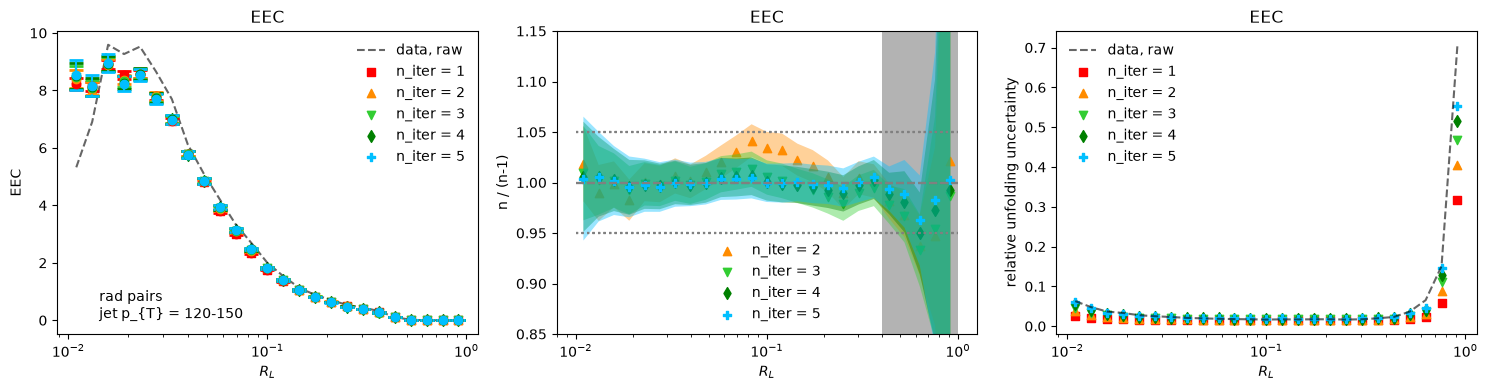

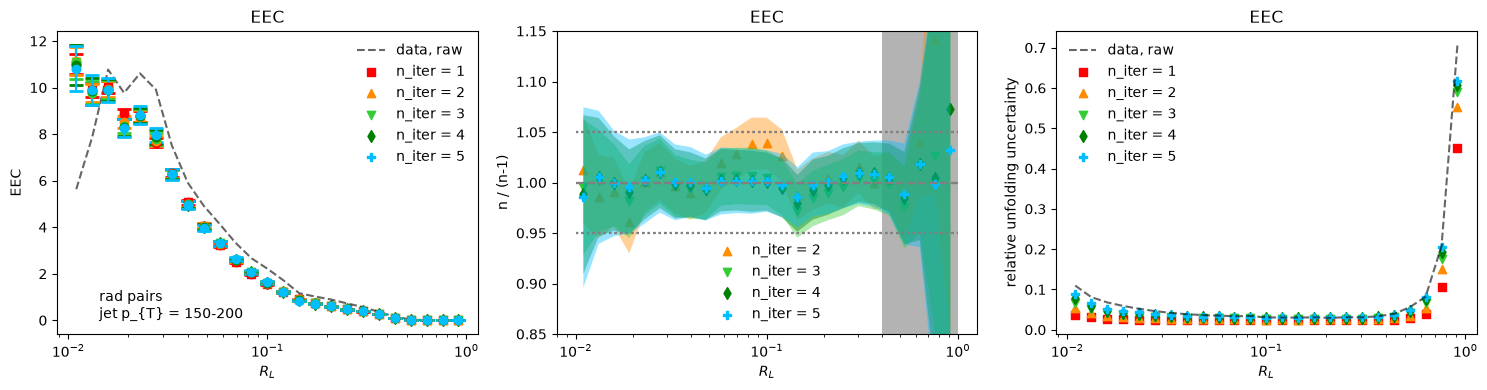

In [65]:
lab = "rad"
h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity = get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm) #, f_prefundold_gen)
matrix1D, matricies = get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true)
print_response_matricies(matrix1D, matricies, binning_reco, binning, labels)

theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err = get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded)
plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                        theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err)
plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning)

plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels)

In [31]:
def getbin(bins, value):
    for i in range(len(bins)-1):
        if bins[i] < value and bins[i+1] > value:
        # binlo = float(np.format_float_positional(bins[i], precision=7, unique=False, fractional=False, trim='k'))
        # binhi = float(np.format_float_positional(bins[i+1], precision=7, unique=False, fractional=False, trim='k'))
        # print(binlo, binhi, value)
        # if binlo <= value and binhi > value:
            return i
    return -1

# print([getbin(R_bins_compare, R_bincenter) for R_bincenter in bincenters[1]])
# print([R_bins_compare[i] for i in [getbin(R_bins_compare, R_bincenter) for R_bincenter in bincenters[1]]])

# h1_EECs_samebinning = [[h1_EECs[ptbin][getbin(R_bincenters_compare, R_bincenter)] for R_bincenter in bincenters[1]] for ptbin in range(len(h1_EECs))]
h1_EECs_samebinning = [[h1_EECs[ptbin][getbin(R_bins_compare[ptbin], R_bincenter)] for R_bincenter in bincenters[1]] for ptbin in range(len(h1_EECs))]
# using R_bins_compare (bin edges) instead of R_bincenters_compare (log bin centers) to decide which data bin to use
h1_EECs_samebinning = np.array(h1_EECs_samebinning)

# h1_EECs_err_samebinning = [[h1_EECs_err[ptbin][getbin(R_bincenters_compare, R_bincenter)] for R_bincenter in bincenters[1]] for ptbin in range(len(h1_EECs))]
h1_EECs_err_samebinning = [[h1_EECs_err[ptbin][getbin(R_bins_compare[ptbin], R_bincenter)] for R_bincenter in bincenters[1]] for ptbin in range(len(h1_EECs))]
h1_EECs_err_samebinning = np.array(h1_EECs_err_samebinning)

# print(h1_EECs_samebinning)
# print(h1_EECs_samebinning.shape)

h1_EECs_err_range = []
for ipt in range(3):
    print(20*(ipt+1), 20*(ipt+2))
    
    h1_EECs_err_range.append([])
    for b in range(len(R_bincenters_compare[ipt])):
        if R_bincenters_compare[ipt][b] > 0.01 and R_bincenters_compare[ipt][b] < 0.4:
            h1_EECs_err_range[ipt].append(h1_EECs_err[ipt][b])
    h1_EECs_err_samebinning_range = []
    for b in range(len(bincenters[1])):
        if bincenters[1][b] > 0.01 and bincenters[1][b] < 0.4:
            h1_EECs_err_samebinning_range.append(h1_EECs_err_samebinning[ipt][b])
    print(h1_EECs_err_range[ipt])
    print(h1_EECs_err_samebinning_range)

20 40
[0.014529287112638593, 0.030593782471729506, 0.015305363522375983, 0.02237437674868906, 0.018806375104320403, 0.016253409723983526, 0.020297503733743547, 0.014366834293923412, 0.016598834218484893, 0.01891640766475601, 0.01924333156919977, 0.014742539812978066, 0.012139719010618359, 0.014923493538961736, 0.015231136437444377, 0.01881832977092891, 0.017463932725941975, 0.020501851062449214, 0.02412187543603487, 0.029566094204674345]
[0.030593782471729506, 0.02237437674868906, 0.016253409723983526, 0.020297503733743547, 0.016598834218484893, 0.01924333156919977, 0.014923493538961736, 0.01881832977092891, 0.020501851062449214, 0.02412187543603487]
40 60
[0.023324770539216905, 0.028824665518444224, 0.025545270523082794, 0.036071904898123536, 0.03713018553672655, 0.03195458607382021, 0.024475235935980687, 0.027529410224216247, 0.02516504949551256, 0.023313483366536096, 0.02152878246036462, 0.02470523195066753, 0.02040921938819421, 0.02403849417430033, 0.022048773268107877, 0.033184151